In [1]:
pip install -q --upgrade "numpy>=1.26" "pandas>=2.0" "scipy>=1.11" "scikit-learn>=1.4" "matplotlib>=3.8" "Pillow>=10.0"

In [2]:
# ── Google Colab: mount Drive 
import sys
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    print('Google Drive mounted.')
else:
    print('Running locally — Drive mount skipped.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive mounted.


In [3]:
import glob
import os
import sys
import time
from itertools import product
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import SplineTransformer, StandardScaler

## 0. Configuration: shared constants

Constants shared by every later section: random seed, data paths, and the three focus states for the case study.

In [4]:
SEED = 42
UPLOAD_DIR = "/content/uploads"   # yearly raw CAMPD CSVs (see Setup, above)
DATA_DIR = "/content/data"        # all derived CSVs are written/read here
FIGURES_DIR = "/content/figures"  # all generated figures are written here
FOCUS_STATES = ["TX", "PA", "CA"]

import os
os.makedirs(UPLOAD_DIR, exist_ok=True)
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

## 1. Core library -- feature engineering

Feature engineering shared by every downstream stage: calendar, CO2-history, and operational-variable construction, plus the leakage-safe `FULL_FEATURES` specification.

In [5]:
RENAME_RAW_COLUMNS = {
    "State": "state", "Facility Name": "facility_name", "Facility ID": "facility_id",
    "Date": "date", "Gross Load (MWh)": "gross_load_mwh", "Steam Load (1000 lb)": "steam_load",
    "SO2 Mass (short tons)": "so2_mass", "CO2 Mass (short tons)": "co2_mass",
    "NOx Mass (short tons)": "nox_mass", "Heat Input (mmBtu)": "heat_input",
}


def _mincount_sum(s: pd.Series) -> float:
    """Sum that returns NaN (not 0) when every value in the group is missing."""
    return s.sum(min_count=1)


def build_state_daily_from_raw(csv_dir):
    """Reconstruct the TX/PA/CA state-day dataset from raw CAMPD yearly exports.

    Mirrors the standalone dataset-construction stage (Section 5 below)
    exactly, so results computed here are directly comparable to the
    manuscript's reported values.
    """
    csv_dir = Path(csv_dir)
    files = sorted(csv_dir.glob("daily-emissions-facility-aggregation*.csv"))
    if not files:
        raise FileNotFoundError(f"No CAMPD exports found in {csv_dir}")
    df = pd.concat([pd.read_csv(f, parse_dates=["Date"]) for f in files], ignore_index=True)
    df.columns = [c.strip() for c in df.columns]
    df = df.drop_duplicates(subset=["State", "Facility ID", "Date"]).rename(columns=RENAME_RAW_COLUMNS)
    df = df[(df["date"] >= "2023-01-01") & (df["date"] <= "2025-12-31")].copy()

    sd = (
        df[df.state.isin(FOCUS_STATES)]
        .groupby(["state", "date"], as_index=False)
        .agg(
            co2_mass=("co2_mass", _mincount_sum),
            so2_mass=("so2_mass", _mincount_sum),
            nox_mass=("nox_mass", _mincount_sum),
            gross_load_mwh=("gross_load_mwh", _mincount_sum),
            heat_input=("heat_input", _mincount_sum),
            n_facilities=("facility_id", "nunique"),
        )
        .sort_values(["state", "date"])
        .reset_index(drop=True)
    )
    return sd


def load_state_daily(path):
    """Load an already-built state-day CSV (columns: state, date, co2_mass, ...)."""
    return pd.read_csv(path, parse_dates=["date"])


# Feature groups are defined once here so that the full-feature model and every
# ablation subset draw from the exact same engineering logic (no duplicated,
# potentially-inconsistent feature code across stages).
CALENDAR_FEATURES = [
    "month_sin", "month_cos", "dow_sin", "dow_cos", "doy_sin", "doy_cos", "is_weekend",
]
LAG_FEATURES = [
    "co2_mass_lag0",
    "co2_mass_lag1", "co2_mass_lag2", "co2_mass_lag3", "co2_mass_lag7",
    "co2_mass_lag14", "co2_mass_lag30",
    "co2_mass_roll7_mean", "co2_mass_roll7_std",
    "co2_mass_roll14_mean", "co2_mass_roll14_std",
    "co2_mass_roll30_mean", "co2_mass_roll30_std",
]
# Split into two groups on a strict criterion: does the quantity algebraically
# contain co2_mass(t)? gross_load, heat_input, so2_mass, nox_mass, n_facilities,
# and heat_per_mwh (= heat_input / load) do not. co2_per_mwh (= co2_mass / load)
# and so2_co2_ratio (= so2_mass / co2_mass) do, by construction. Both are
# excluded from FULL_FEATURES (the primary specification given to every model).
# co2_mass(t) itself is included directly as co2_mass_lag0 (it is known at
# forecast origin t, exactly as the persistence baseline uses it) -- so
# retaining co2_per_mwh/so2_co2_ratio alongside it and load(t) would add no
# new information but would let a nonlinear model reconstruct co2_mass(t) as
# an interaction of two OTHER features (load(t) x intensity(t)) that a linear
# model cannot form, an asymmetry between model families that has nothing to
# do with genuine nonlinear skill. They are retained only in
# CURRENT_EMISSIONS_TRANSFORM_FEATURES, used exclusively in the dedicated
# leakage ablation, never in the primary "full" specification.
TARGET_INDEPENDENT_OPERATIONAL_FEATURES = [
    "gross_load_mwh", "heat_input", "so2_mass", "nox_mass", "n_facilities", "heat_per_mwh",
]
CURRENT_EMISSIONS_TRANSFORM_FEATURES = [
    "co2_per_mwh", "so2_co2_ratio",
]
FULL_FEATURES = (
    CALENDAR_FEATURES + ["year"] + LAG_FEATURES + TARGET_INDEPENDENT_OPERATIONAL_FEATURES
)

FEATURE_GROUPS = {
    "calendar_only": CALENDAR_FEATURES + ["year"],
    "co2_history_only": LAG_FEATURES,
    "target_independent_operational_only": TARGET_INDEPENDENT_OPERATIONAL_FEATURES,
    "current_emissions_transforms_only": CURRENT_EMISSIONS_TRANSFORM_FEATURES,
    "co2_history_plus_operational": LAG_FEATURES + TARGET_INDEPENDENT_OPERATIONAL_FEATURES,
    "full": FULL_FEATURES,
}


def engineer_features(state_df):
    """Add calendar, lag/rolling, and operational-ratio features to one state's daily series.

    d[t] uses only information available at or before t (lag/rolling features are
    shifted by at least 1 day before the window is computed), so no leakage from
    the forecast target enters the feature set.
    """
    d = state_df.sort_values("date").copy().reset_index(drop=True)
    d["day_of_week"] = d["date"].dt.dayofweek
    d["month"] = d["date"].dt.month
    d["year"] = d["date"].dt.year
    d["day_of_year"] = d["date"].dt.dayofyear
    d["is_weekend"] = (d["day_of_week"] >= 5).astype(int)
    d["month_sin"] = np.sin(2 * np.pi * d["month"] / 12)
    d["month_cos"] = np.cos(2 * np.pi * d["month"] / 12)
    d["dow_sin"] = np.sin(2 * np.pi * d["day_of_week"] / 7)
    d["dow_cos"] = np.cos(2 * np.pi * d["day_of_week"] / 7)
    d["doy_sin"] = np.sin(2 * np.pi * d["day_of_year"] / 365.25)
    d["doy_cos"] = np.cos(2 * np.pi * d["day_of_year"] / 365.25)
    for lag in [0, 1, 2, 3, 7, 14, 30]:
        d[f"co2_mass_lag{lag}"] = d["co2_mass"].shift(lag)
    for w in [7, 14, 30]:
        d[f"co2_mass_roll{w}_mean"] = d["co2_mass"].shift(1).rolling(w).mean()
        d[f"co2_mass_roll{w}_std"] = d["co2_mass"].shift(1).rolling(w).std()
    d["co2_per_mwh"] = d["co2_mass"] / (d["gross_load_mwh"] + 1)
    d["so2_co2_ratio"] = d["so2_mass"] / (d["co2_mass"] + 1)
    d["heat_per_mwh"] = d["heat_input"] / (d["gross_load_mwh"] + 1)
    return d


def make_xy(state_df, feature_cols, horizon=1):
    """Build (X, y_target, y_current, dates) for a given horizon, dropping rows
    with insufficient lag history. y_target is the actual CO2 mass at t+horizon;
    y_current is CO2 mass at t (used for the persistence baseline)."""
    d = engineer_features(state_df)
    d = d.dropna(subset=feature_cols + ["co2_mass"]).reset_index(drop=True)
    X = d[feature_cols].to_numpy()
    y_target = d["co2_mass"].shift(-horizon).to_numpy()
    y_current = d["co2_mass"].to_numpy()
    dates = d["date"].to_numpy()
    X, y_target, y_current, dates = X[:-horizon], y_target[:-horizon], y_current[:-horizon], dates[:-horizon]
    return X, y_target, y_current, dates


def chronological_split(n, train_frac=0.70, val_frac=0.15):
    n_train = int(n * train_frac)
    n_val = int(n * val_frac)
    return n_train, n_val, n - n_train - n_val

## 2. Core library -- forecasting models (Ridge, HGB)

Only models that could be executed and independently verified in this
authoring environment are implemented here (Ridge, HistGradientBoosting,
persistence). XGBoost and the PyTorch LSTM/LSTM-autoencoder results
reported in the manuscript were produced in a separate environment and
are NOT recomputed by this module -- see the manuscript's Limitations
section for the reproducibility scope of each model family.

In [6]:
def metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = y_true != 0
    return {
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "MAPE": float(np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100),
        "R2": float(r2_score(y_true, y_pred)),
    }


def fit_predict_ridge(X_train, y_train, X_test, alpha=1.0):
    scaler = StandardScaler().fit(X_train)
    model = Ridge(alpha=alpha, random_state=SEED).fit(scaler.transform(X_train), y_train)
    return model.predict(scaler.transform(X_test)), model


def fit_predict_hgb(X_train, y_train, X_test, learning_rate=0.06,
                     max_depth=3, max_iter=120, min_samples_leaf=14):
    model = HistGradientBoostingRegressor(
        random_state=SEED, learning_rate=learning_rate, max_depth=max_depth,
        max_iter=max_iter, min_samples_leaf=min_samples_leaf,
    ).fit(X_train, y_train)
    return model.predict(X_test), model


# Hyperparameter grids given equal search effort to both model families: 12
# ridge alpha values (RIDGE_ALPHA_GRID, Section 3 below), 12 HGB
# configurations here, so neither model is tuned on a materially larger
# budget than the other.
HGB_GRID = [
    {"learning_rate": 0.03, "max_depth": 2, "max_iter": 100, "min_samples_leaf": 10},
    {"learning_rate": 0.03, "max_depth": 3, "max_iter": 150, "min_samples_leaf": 14},
    {"learning_rate": 0.03, "max_depth": 4, "max_iter": 150, "min_samples_leaf": 20},
    {"learning_rate": 0.06, "max_depth": 2, "max_iter": 80, "min_samples_leaf": 10},
    {"learning_rate": 0.06, "max_depth": 3, "max_iter": 120, "min_samples_leaf": 14},
    {"learning_rate": 0.06, "max_depth": 4, "max_iter": 120, "min_samples_leaf": 20},
    {"learning_rate": 0.06, "max_depth": 5, "max_iter": 100, "min_samples_leaf": 25},
    {"learning_rate": 0.1, "max_depth": 2, "max_iter": 80, "min_samples_leaf": 10},
    {"learning_rate": 0.1, "max_depth": 3, "max_iter": 100, "min_samples_leaf": 14},
    {"learning_rate": 0.1, "max_depth": 4, "max_iter": 80, "min_samples_leaf": 20},
    {"learning_rate": 0.15, "max_depth": 3, "max_iter": 80, "min_samples_leaf": 14},
    {"learning_rate": 0.15, "max_depth": 4, "max_iter": 60, "min_samples_leaf": 25},
]

## 3. Core library -- symmetric hyperparameter selection

Both ridge and HGB are searched over a 12-point grid, scored on an
internal chronological validation split carved out of whatever data is
supplied, and the winner is selected by validation R2. Both models
therefore receive an equal search budget and identical temporal
model-selection treatment (only past-relative-to-the-validation-window
data is used).

Used in two places, each with a data window chosen so that no forecast
in the resulting evaluation ever uses information from after its own
origin:
- Single-split benchmark: selection window = the single split's own
train+validation partition (already prospective relative to its
test set).
- Rolling-origin backtest: selection window = only the initial window
available before the backtest's first forecast origin, so the SAME
frozen hyperparameters are used at every rolling origin without
ever having been chosen using data from after that origin.

In [7]:
RIDGE_ALPHA_GRID = [0.1, 0.3, 1, 3, 10, 30, 50, 100, 200, 300, 500, 1000]


def select_hyperparameters(X, y, val_frac=0.15):
    """Split (X, y) chronologically into inner-train/inner-validation, search
    both grids on the inner split, return the selected ridge alpha and HGB
    config dict, plus each model's validation R2 for reference."""
    n = len(X)
    n_val = max(int(n * val_frac), 20)
    n_tr = n - n_val
    Xtr, ytr = X[:n_tr], y[:n_tr]
    Xv, yv = X[n_tr:], y[n_tr:]

    best_alpha, best_ridge_r2 = None, -np.inf
    for a in RIDGE_ALPHA_GRID:
        pred, _ = fit_predict_ridge(Xtr, ytr, Xv, alpha=a)
        r2 = metrics(yv, pred)["R2"]
        if r2 > best_ridge_r2:
            best_alpha, best_ridge_r2 = a, r2

    best_hgb_cfg, best_hgb_r2 = None, -np.inf
    for cfg in HGB_GRID:
        pred, _ = fit_predict_hgb(Xtr, ytr, Xv, **cfg)
        r2 = metrics(yv, pred)["R2"]
        if r2 > best_hgb_r2:
            best_hgb_cfg, best_hgb_r2 = cfg, r2

    return {
        "ridge_alpha": best_alpha, "ridge_val_r2": round(best_ridge_r2, 4),
        "hgb_config": best_hgb_cfg, "hgb_val_r2": round(best_hgb_r2, 4),
        "n_inner_train": n_tr, "n_inner_val": n_val,
    }

## 4. Core library -- dependent-error statistical tests

Implements corrections to a naive iid-bootstrap / independence-assuming
testing approach, which would be invalid given that adjacent daily
forecast errors are serially correlated:

1. Moving-block bootstrap: resamples contiguous blocks of the test-set
error series (rather than individual points), preserving short-range
serial correlation when constructing confidence intervals.

2. Diebold-Mariano test with a Newey-West HAC variance estimator: the
standard test for comparing the predictive accuracy of two forecasts
when the loss-differential series is itself autocorrelated
(Diebold & Mariano, 1995), with the Harvey-Leybourne-Newbold (1997)
small-sample correction applied throughout.

No external time-series package (e.g. statsmodels) is used; both the
Newey-West estimator and the DM statistic are implemented directly from
their definitions so the computation is fully auditable.

In [8]:
def moving_block_bootstrap_ci(errors_a, errors_b, block_len, n_boot=2000, seed=42,
                                stat_fn=None):
    """95% CI for mean(stat_fn(errors_a)) - mean(stat_fn(errors_b)) via moving-block
    bootstrap. If stat_fn is None, compares raw error levels directly (e.g., for
    RMSE/MAE deltas, pass squared or absolute errors as errors_a/errors_b)."""
    rng = np.random.default_rng(seed)
    errors_a = np.asarray(errors_a, dtype=float)
    errors_b = np.asarray(errors_b, dtype=float)
    n = len(errors_a)
    n_blocks = int(np.ceil(n / block_len))
    diffs = []
    for _ in range(n_boot):
        starts = rng.integers(0, n - block_len + 1, n_blocks)
        idx = np.concatenate([np.arange(s, s + block_len) for s in starts])[:n]
        diffs.append(errors_a[idx].mean() - errors_b[idx].mean())
    diffs = np.array(diffs)
    return {
        "mean_diff": float(errors_a.mean() - errors_b.mean()),
        "ci_lo95": float(np.percentile(diffs, 2.5)),
        "ci_hi95": float(np.percentile(diffs, 97.5)),
    }


def newey_west_variance(d, max_lag):
    """Newey-West (1987) HAC variance of the sample mean of series d."""
    d = np.asarray(d, dtype=float)
    n = len(d)
    d_c = d - d.mean()
    gamma0 = np.sum(d_c ** 2) / n
    var = gamma0
    for lag in range(1, max_lag + 1):
        w = 1.0 - lag / (max_lag + 1)  # Bartlett kernel
        gamma_lag = np.sum(d_c[lag:] * d_c[:-lag]) / n
        var += 2 * w * gamma_lag
    return var / n  # variance of the mean, not of d itself


def diebold_mariano_test(errors_a, errors_b, loss="squared", max_lag=None, horizon=1):
    """Diebold-Mariano test comparing forecast A vs forecast B on the same
    target series. d_t = L(e_a,t) - L(e_b,t); H0: E[d_t] = 0 (equal accuracy).
    A positive DM statistic means A has higher loss (worse) than B.
    max_lag defaults to max(horizon-1, floor(4*(n/100)^(2/9))): for
    multi-step-ahead forecasts, adjacent errors can be correlated through the
    overlapping horizon itself, so the truncation lag should never be
    shorter than horizon-1 even when the standard Newey-West rule would pick
    something smaller.

    Applies the Harvey, Leybourne & Newbold (1997) small-sample correction:
    DM* = DM * sqrt[(n + 1 - 2h + h(h-1)/n) / n], referred to a Student-t
    distribution with n-1 degrees of freedom rather than the asymptotic
    standard normal used by the uncorrected statistic. This is the variant
    actually computed and reported throughout this analysis."""
    errors_a = np.asarray(errors_a, dtype=float)
    errors_b = np.asarray(errors_b, dtype=float)
    n = len(errors_a)
    if loss == "squared":
        La, Lb = errors_a ** 2, errors_b ** 2
    elif loss == "absolute":
        La, Lb = np.abs(errors_a), np.abs(errors_b)
    else:
        raise ValueError("loss must be 'squared' or 'absolute'")
    d = La - Lb
    if max_lag is None:
        standard_rule = max(1, int(np.floor(4 * (n / 100) ** (2 / 9))))
        max_lag = max(horizon - 1, standard_rule)
    var_dbar = newey_west_variance(d, max_lag)
    dbar = d.mean()
    dm_stat = dbar / np.sqrt(var_dbar)

    hln_factor = np.sqrt(max((n + 1 - 2 * horizon + horizon * (horizon - 1) / n) / n, 0.0))
    dm_star = dm_stat * hln_factor
    p_value = 2 * (1 - stats.t.cdf(np.abs(dm_star), df=n - 1))
    return {
        "n": n, "max_lag": max_lag, "mean_loss_diff": float(dbar),
        "DM_statistic": float(dm_star), "DM_statistic_uncorrected": float(dm_stat),
        "p_value": float(p_value),
    }


def holm_correction(p_values):
    """Holm-Bonferroni step-down correction. Returns adjusted p-values in the
    original order, controlling the family-wise error rate across all tests
    passed in together."""
    p_values = np.asarray(p_values, dtype=float)
    m = len(p_values)
    order = np.argsort(p_values)
    adjusted_sorted = np.empty(m)
    running_max = 0.0
    for i, idx in enumerate(order):
        val = min((m - i) * p_values[idx], 1.0)
        running_max = max(running_max, val)
        adjusted_sorted[i] = running_max
    adjusted = np.empty(m)
    adjusted[order] = adjusted_sorted
    return adjusted


def benjamini_hochberg(p_values):
    """Benjamini-Hochberg FDR correction. Returns adjusted q-values in the
    original order."""
    p_values = np.asarray(p_values, dtype=float)
    m = len(p_values)
    order = np.argsort(p_values)
    ranked = p_values[order]
    q_sorted = ranked * m / (np.arange(m) + 1)
    q_sorted = np.minimum.accumulate(q_sorted[::-1])[::-1]
    q_sorted = np.minimum(q_sorted, 1.0)
    q = np.empty(m)
    q[order] = q_sorted
    return q


def hac_regression_test(y, x, max_lag=None):
    """Simple OLS of y on x (with intercept), with a Newey-West HAC standard
    error on the slope, used to test H0: beta_1 = 0 for the ramp-mechanism
    regression: y = squared-error differential, x = |ramp|."""
    y = np.asarray(y, dtype=float)
    x = np.asarray(x, dtype=float)
    n = len(y)
    X = np.column_stack([np.ones(n), x])
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    resid = y - X @ beta
    # HAC "sandwich" variance for OLS: (X'X)^-1 S (X'X)^-1, S built from a
    # Newey-West-weighted sum of the score contributions X_i * resid_i.
    if max_lag is None:
        max_lag = max(1, int(np.floor(4 * (n / 100) ** (2 / 9))))
    XtX_inv = np.linalg.inv(X.T @ X)
    scores = X * resid[:, None]
    S = scores.T @ scores
    for lag in range(1, max_lag + 1):
        w = 1.0 - lag / (max_lag + 1)
        Gamma = scores[lag:].T @ scores[:-lag]
        S += w * (Gamma + Gamma.T)
    cov = XtX_inv @ S @ XtX_inv
    se = np.sqrt(np.diag(cov))
    t_stat = beta / se
    p_value = 2 * (1 - stats.norm.cdf(np.abs(t_stat)))
    return {
        "beta0": float(beta[0]), "beta1": float(beta[1]),
        "se_beta1": float(se[1]), "t_beta1": float(t_stat[1]), "p_beta1": float(p_value[1]),
        "max_lag": max_lag, "n": n,
    }

## 5. Dataset construction: TX / PA / CA, 2023-2025

Builds the 2023-2025 TX/PA/CA state-day analysis dataset from annual EPA
CAMPD facility exports. Place the three
daily-emissions-facility-aggregation*.csv files in UPLOAD_DIR and call
main_build_dataset().

In [9]:
def main_build_dataset(src_dir=UPLOAD_DIR, out_dir=DATA_DIR):
    src = Path(src_dir)
    out = Path(out_dir)
    out.mkdir(parents=True, exist_ok=True)
    csvs = sorted(src.glob("daily-emissions-facility-aggregation*.csv"))
    if not csvs:
        raise FileNotFoundError("No CAMPD daily facility aggregation CSVs found.")
    df = pd.concat([pd.read_csv(f, parse_dates=["Date"]) for f in csvs], ignore_index=True)
    df.columns = [c.strip() for c in df.columns]
    n_before = len(df)
    df = df.drop_duplicates(subset=["State", "Facility ID", "Date"]).copy()
    dup_removed = n_before - len(df)
    df = df.rename(columns=RENAME_RAW_COLUMNS)
    df = df[(df["date"] >= "2023-01-01") & (df["date"] <= "2025-12-31")].copy()
    pd.DataFrame({
        "Metric": ["Rows before duplicate removal", "Duplicate rows removed", "Rows in 2023-2025 analysis",
                   "Unique states", "Unique facilities", "Start date", "End date"],
        "Value": [n_before, dup_removed, len(df), df.state.nunique(), df.facility_id.nunique(),
                  str(df.date.min().date()), str(df.date.max().date())]
    }).to_csv(out / "dataset_audit.csv", index=False)
    pd.DataFrame({
        "Column": df.columns,
        "Missing_count": [df[c].isna().sum() for c in df.columns],
        "Missing_percent": [100 * df[c].isna().mean() for c in df.columns]
    }).to_csv(out / "facility_level_missingness.csv", index=False)
    sd = (df[df.state.isin(FOCUS_STATES)].groupby(["state", "date"], as_index=False)
          .agg(co2_mass=("co2_mass", _mincount_sum), so2_mass=("so2_mass", _mincount_sum),
               nox_mass=("nox_mass", _mincount_sum), gross_load_mwh=("gross_load_mwh", _mincount_sum),
               heat_input=("heat_input", _mincount_sum), n_facilities=("facility_id", "nunique"))
          .sort_values(["state", "date"]))
    sd.to_csv(out / "state_daily_TX_PA_CA_2023_2025.csv", index=False)
    annual = (sd.assign(year=sd.date.dt.year).groupby(["state", "year"], as_index=False)
              .agg(co2_short_tons=("co2_mass", "sum"), so2_short_tons=("so2_mass", "sum"),
                   nox_short_tons=("nox_mass", "sum"), gross_load_mwh=("gross_load_mwh", "sum"),
                   heat_input_mmbtu=("heat_input", "sum"), mean_daily_co2=("co2_mass", "mean"),
                   sd_daily_co2=("co2_mass", "std")))
    annual["co2_intensity_short_ton_per_mwh"] = annual.co2_short_tons / annual.gross_load_mwh
    annual.to_csv(out / "annual_state_summary.csv", index=False)

## 6. Three-state case study: single-split benchmark

One-day and seven-day single chronological split benchmark, using
FULL_FEATURES and symmetric, prospective hyperparameter selection for
both ridge and HGB (selected on the split's own train+validation
partition, entirely prior to its test partition).

In [10]:
def run_horizon_single_split(sd, horizon):
    rows, hp_rows = [], []
    for state in FOCUS_STATES:
        X, y, y_curr, dates = make_xy(sd[sd.state == state], FULL_FEATURES, horizon=horizon)
        n_tr, n_val, n_te = chronological_split(len(X))
        Xtrval, ytrval = X[:n_tr + n_val], y[:n_tr + n_val]
        Xte, yte, ycte = X[n_tr + n_val:], y[n_tr + n_val:], y_curr[n_tr + n_val:]

        hp = select_hyperparameters(Xtrval, ytrval, val_frac=n_val / (n_tr + n_val))
        pred_ridge, _ = fit_predict_ridge(Xtrval, ytrval, Xte, alpha=hp["ridge_alpha"])
        pred_hgb, _ = fit_predict_hgb(Xtrval, ytrval, Xte, **hp["hgb_config"])

        hp_rows.append({"State": state, "Horizon": horizon, "N_test": len(yte),
                         **{k: v for k, v in hp.items() if k != "hgb_config"},
                         "hgb_config": str(hp["hgb_config"])})
        for name, pred in [("Persistence", ycte), ("Ridge", pred_ridge), ("HistGradientBoosting", pred_hgb)]:
            m = metrics(yte, pred)
            rows.append({"State": state, "Horizon": horizon, "Model": name, "N_test": len(yte), **m})
    return pd.DataFrame(rows), pd.DataFrame(hp_rows)


def main_single_split():
    sd = load_state_daily(Path(DATA_DIR) / "state_daily_TX_PA_CA_2023_2025.csv")
    all_results, all_hp = [], []
    for horizon in [1, 7]:
        res, hp = run_horizon_single_split(sd, horizon)
        all_results.append(res)
        all_hp.append(hp)
    results = pd.concat(all_results, ignore_index=True)
    hp_log = pd.concat(all_hp, ignore_index=True)
    results.to_csv(Path(DATA_DIR) / "single_split_benchmark.csv", index=False)
    hp_log.to_csv(Path(DATA_DIR) / "single_split_hyperparameter_log.csv", index=False)
    print(hp_log.to_string(index=False))
    print()
    print(results.round(4).to_string(index=False))

## 7. Three-state case study: rolling-origin backtest

Expanding-window rolling-origin backtest. Ridge and HGB hyperparameters
are selected ONCE, using only the data available before the backtest's
first forecast origin (an internal 85/15 chronological split of that
initial 50% window), then frozen and reused at every subsequent origin.
This is what makes the backtest fully prospective: no forecast, at any
origin, is ever produced using a hyperparameter chosen with the benefit
of information from after that origin.

In [11]:
STEP_TWO_HORIZON = 7
MIN_TRAIN_FRAC = 0.50


def backtest_state_three_year(sd, state, horizon):
    X, y, y_curr, dates = make_xy(sd[sd.state == state], FULL_FEATURES, horizon=horizon)
    n = len(X)
    n_min_train = int(n * MIN_TRAIN_FRAC)

    # Hyperparameters are selected ONCE, here, using only rows [0, n_min_train)
    # -- strictly before the first rolling-origin forecast -- then frozen.
    hp = select_hyperparameters(X[:n_min_train], y[:n_min_train], val_frac=0.15)

    records = []
    origin = n_min_train
    while origin < n:
        end = min(origin + STEP_TWO_HORIZON, n)
        Xtr, ytr = X[:origin], y[:origin]
        Xte, yte, ycte = X[origin:end], y[origin:end], y_curr[origin:end]
        dte = dates[origin:end]
        if len(Xte) == 0:
            break
        pred_ridge, _ = fit_predict_ridge(Xtr, ytr, Xte, alpha=hp["ridge_alpha"])
        pred_hgb, _ = fit_predict_hgb(Xtr, ytr, Xte, **hp["hgb_config"])
        for i in range(len(Xte)):
            records.append({
                "state": state, "horizon": horizon, "date": dte[i], "n_train": origin,
                "y_true": yte[i], "y_persist": ycte[i],
                "pred_ridge": pred_ridge[i], "pred_hgb": pred_hgb[i],
            })
        origin = end
    return pd.DataFrame(records), hp


def main_rolling_origin():
    sd = load_state_daily(Path(DATA_DIR) / "state_daily_TX_PA_CA_2023_2025.csv")
    for horizon in [1, 7]:
        all_records, hp_rows = [], []
        for state in FOCUS_STATES:
            df, hp = backtest_state_three_year(sd, state, horizon)
            all_records.append(df)
            hp_rows.append({"State": state, "Horizon": horizon,
                             "ridge_alpha": hp["ridge_alpha"], "ridge_val_r2": hp["ridge_val_r2"],
                             "hgb_config": str(hp["hgb_config"]), "hgb_val_r2": hp["hgb_val_r2"],
                             "n_selection_train": hp["n_inner_train"], "n_selection_val": hp["n_inner_val"]})

        full_df = pd.concat(all_records, ignore_index=True)
        suffix = "" if horizon == 1 else "_7day"
        full_df.to_csv(Path(DATA_DIR) / f"rolling_origin_predictions{suffix}.csv", index=False)
        pd.DataFrame(hp_rows).to_csv(Path(DATA_DIR) / f"rolling_origin_hyperparameter_log{suffix}.csv", index=False)

        summary_rows = []
        for state in FOCUS_STATES:
            sub = full_df[full_df.state == state]
            n_origins = sub["n_train"].nunique()
            for name, col in [("Persistence", "y_persist"), ("Ridge", "pred_ridge"), ("HistGradientBoosting", "pred_hgb")]:
                m = metrics(sub["y_true"], sub[col])
                summary_rows.append({"State": state, "Horizon": horizon, "Model": name,
                                      "N_forecasts": len(sub), "N_refit_origins": n_origins, **m})
        summary_df = pd.DataFrame(summary_rows)
        summary_df.to_csv(Path(DATA_DIR) / f"rolling_origin_summary{suffix}.csv", index=False)
        print(f"=== Horizon {horizon} ===")
        print(pd.DataFrame(hp_rows).to_string(index=False))
        print(summary_df.round(4).to_string(index=False))
        print(f"Date range: {full_df.date.min()} to {full_df.date.max()}, N per state: {len(full_df)//3}")
        print()

## 8. CA reversal decomposition (2x2 factorial)

Isolates which of two methodological corrections actually drove the CA
one-day ridge-vs-HGB reversal, via a 2x2 factorial: {old feature set,
new feature set} x {old (leaky) alpha selection, new (prospective,
frozen) alpha selection}, holding HGB's configuration fixed at a single
default across all four cells so the comparison isolates only these two
factors.

Feature factor:
OLD_FEATURES = calendar + year + lag1..30 + rolling stats (no lag0)
+ gross_load, heat_input, co2_per_mwh, so2_co2_ratio, heat_per_mwh
NEW_FEATURES = FULL_FEATURES (lag0 explicit; no co2_per_mwh/so2_co2_ratio)

Alpha-selection factor:
OLD_ALPHA = selected once on the single split's own validation window
(chronologically AFTER many rolling-origin origins), then
reused for the entire rolling-origin backtest (the leak).
NEW_ALPHA = selected once on data strictly before the rolling-origin
backtest's first origin, then frozen.

In [12]:
CA_DECOMPOSITION_STATE = "CA"
CA_DECOMPOSITION_HGB_FIXED = dict(learning_rate=0.06, max_depth=3, max_iter=120, min_samples_leaf=14)

OLD_FEATURES_PRE_CORRECTION = (
    ["month_sin", "month_cos", "dow_sin", "dow_cos", "doy_sin", "doy_cos", "is_weekend", "year"]
    + ["co2_mass_lag1", "co2_mass_lag2", "co2_mass_lag3", "co2_mass_lag7", "co2_mass_lag14", "co2_mass_lag30",
       "co2_mass_roll7_mean", "co2_mass_roll7_std", "co2_mass_roll14_mean", "co2_mass_roll14_std",
       "co2_mass_roll30_mean", "co2_mass_roll30_std"]
    + ["gross_load_mwh", "heat_input", "co2_per_mwh", "so2_co2_ratio", "heat_per_mwh"]
)


def select_alpha_only(Xtr, ytr, Xv, yv):
    best_alpha, best_r2 = None, -np.inf
    for a in RIDGE_ALPHA_GRID:
        pred, _ = fit_predict_ridge(Xtr, ytr, Xv, alpha=a)
        r2 = metrics(yv, pred)["R2"]
        if r2 > best_r2:
            best_alpha, best_r2 = a, r2
    return best_alpha


def run_ca_decomposition_cell(sd, feature_cols, alpha_mode):
    X, y, y_curr, dates = make_xy(sd, feature_cols, horizon=1)
    n = len(X)

    if alpha_mode == "old_leaky":
        # Select alpha on the SINGLE SPLIT's own validation window
        # (chronologically late in the series), then reuse it for the
        # whole rolling-origin backtest.
        n_tr, n_val, n_te = chronological_split(n)
        Xtr, ytr = X[:n_tr], y[:n_tr]
        Xv, yv = X[n_tr:n_tr + n_val], y[n_tr:n_tr + n_val]
        alpha = select_alpha_only(Xtr, ytr, Xv, yv)
    elif alpha_mode == "new_prospective":
        # Select alpha ONLY on data before the rolling-origin backtest begins.
        n_min_train = int(n * MIN_TRAIN_FRAC)
        n_inner_val = max(int(n_min_train * 0.15), 20)
        n_inner_tr = n_min_train - n_inner_val
        Xtr, ytr = X[:n_inner_tr], y[:n_inner_tr]
        Xv, yv = X[n_inner_tr:n_min_train], y[n_inner_tr:n_min_train]
        alpha = select_alpha_only(Xtr, ytr, Xv, yv)
    else:
        raise ValueError(alpha_mode)

    n_min_train = int(n * MIN_TRAIN_FRAC)
    preds_r, preds_h, actuals = [], [], []
    origin = n_min_train
    while origin < n:
        end = min(origin + STEP_TWO_HORIZON, n)
        Xtr, ytr = X[:origin], y[:origin]
        Xte, yte = X[origin:end], y[origin:end]
        if len(Xte) == 0:
            break
        pr, _ = fit_predict_ridge(Xtr, ytr, Xte, alpha=alpha)
        ph, _ = fit_predict_hgb(Xtr, ytr, Xte, **CA_DECOMPOSITION_HGB_FIXED)
        preds_r.extend(pr); preds_h.extend(ph); actuals.extend(yte)
        origin = end

    actuals = np.array(actuals); preds_r = np.array(preds_r); preds_h = np.array(preds_h)
    m_r = metrics(actuals, preds_r); m_h = metrics(actuals, preds_h)
    er, eh = actuals - preds_r, actuals - preds_h
    dm = diebold_mariano_test(er, eh, loss="squared")
    return {"alpha": alpha, "R2_ridge": m_r["R2"], "R2_HGB": m_h["R2"],
            "DM_stat": dm["DM_statistic"], "DM_p": dm["p_value"], "n": len(actuals)}


def main_ca_decomposition():
    sd_all = load_state_daily(Path(DATA_DIR) / "state_daily_TX_PA_CA_2023_2025.csv")
    sd = sd_all[sd_all.state == CA_DECOMPOSITION_STATE]

    rows = []
    for feat_name, feat_cols in [("old_leaky_features", OLD_FEATURES_PRE_CORRECTION), ("new_fixed_features", FULL_FEATURES)]:
        for alpha_name in ["old_leaky", "new_prospective"]:
            res = run_ca_decomposition_cell(sd, feat_cols, alpha_name)
            rows.append({"Features": feat_name, "Alpha_selection": alpha_name, **res})
            print(f"{feat_name:22s} x {alpha_name:16s}: alpha={res['alpha']:>6}  "
                  f"R2_ridge={res['R2_ridge']:.4f}  R2_HGB={res['R2_HGB']:.4f}  "
                  f"DM={res['DM_stat']:+.3f}  p={res['DM_p']:.4f}")

    df = pd.DataFrame(rows)
    df.to_csv(Path(DATA_DIR) / "ca_reversal_decomposition.csv", index=False)

## 9. Nationwide eligibility screening, 2023-2025 (47 states)

Builds the state-day series for all 51 state/district codes in the
CAMPD extract and applies eligibility criteria, set before any model is
fit, to select the states used in the two-horizon nationwide benchmark.

Criteria (all must hold over the full 1,096-day window, 2023-2025):
1. Data completeness: state-day CO2 mass observed on >=98% of days.
2. Minimum reporting facilities: >=5 unique facilities ever reporting.
3. Sufficient emissions volume: mean daily CO2 mass >= 5,000 short tons.
4. Sufficient variance: CV (SD/mean) of daily CO2 mass >= 0.05.
5. No pathological discontinuities: no gap of >14 consecutive missing days.

These are set from data-quality/statistical considerations alone, before
any ridge/HGB comparison is run, so the eligible-state list cannot be
influenced by which states produce a more or less interesting result.

In [13]:
ELIGIBILITY_MIN_COMPLETENESS = 0.98
ELIGIBILITY_MIN_FACILITIES = 5
ELIGIBILITY_MIN_MEAN_CO2 = 5000
ELIGIBILITY_MIN_CV = 0.05
ELIGIBILITY_MAX_GAP_DAYS = 14


def load_raw_nationwide(upload_dir=UPLOAD_DIR):
    files = sorted(glob.glob(f"{upload_dir}/daily-emissions-facility-aggregation-*.csv"))
    files = [f for f in files if "592fc217" not in f]
    raw = pd.concat([pd.read_csv(f, parse_dates=["Date"]) for f in files], ignore_index=True)
    raw.columns = [c.strip() for c in raw.columns]
    raw = raw.drop_duplicates(subset=["State", "Facility ID", "Date"])
    raw = raw[(raw.Date >= "2023-01-01") & (raw.Date <= "2025-12-31")]
    raw = raw.rename(columns=RENAME_RAW_COLUMNS)
    return raw


def build_state_daily_reindexed(raw, state, start="2023-01-01", end="2025-12-31"):
    sub = raw[raw.state == state]
    sd = (sub.groupby("date", as_index=False)
          .agg(co2_mass=("co2_mass", _mincount_sum), so2_mass=("so2_mass", _mincount_sum),
               nox_mass=("nox_mass", _mincount_sum), gross_load_mwh=("gross_load_mwh", _mincount_sum),
               heat_input=("heat_input", _mincount_sum), n_facilities=("facility_id", "nunique")))
    sd["state"] = state
    full_index = pd.date_range(start, end, freq="D")
    sd = sd.set_index("date").reindex(full_index)
    sd.index.name = "date"
    return sd.reset_index()


def max_consecutive_gap(co2_series):
    is_missing = co2_series.isna().to_numpy()
    max_gap, cur = 0, 0
    for m in is_missing:
        if m:
            cur += 1
            max_gap = max(max_gap, cur)
        else:
            cur = 0
    return max_gap


def main_nationwide_eligibility():
    out_dir = Path(DATA_DIR)
    os.makedirs(out_dir / "nationwide_state_daily", exist_ok=True)
    raw = load_raw_nationwide()
    states = sorted(raw.state.unique())
    n_days = 1096

    rows = []
    all_state_daily = {}
    for state in states:
        sd = build_state_daily_reindexed(raw, state)
        all_state_daily[state] = sd
        n_complete = sd.co2_mass.notna().sum()
        completeness = n_complete / n_days
        n_facilities = raw[raw.state == state].facility_id.nunique()
        mean_co2 = sd.co2_mass.mean()
        sd_co2 = sd.co2_mass.std()
        cv = sd_co2 / mean_co2 if mean_co2 and mean_co2 > 0 else np.nan
        max_gap = max_consecutive_gap(sd.co2_mass)

        eligible = (
            completeness >= ELIGIBILITY_MIN_COMPLETENESS
            and n_facilities >= ELIGIBILITY_MIN_FACILITIES
            and (mean_co2 or 0) >= ELIGIBILITY_MIN_MEAN_CO2
            and (cv or 0) >= ELIGIBILITY_MIN_CV
            and max_gap <= ELIGIBILITY_MAX_GAP_DAYS
        )
        rows.append({
            "state": state, "n_facilities": n_facilities, "completeness": round(completeness, 4),
            "mean_daily_co2": round(mean_co2, 1) if pd.notna(mean_co2) else np.nan,
            "cv": round(cv, 4) if pd.notna(cv) else np.nan,
            "max_consecutive_gap_days": max_gap, "eligible": eligible,
        })

    elig_df = pd.DataFrame(rows).sort_values("mean_daily_co2", ascending=False)
    elig_df.to_csv(out_dir / "nationwide_eligibility.csv", index=False)
    print(elig_df.to_string(index=False))
    n_eligible = elig_df.eligible.sum()
    print(f"Eligible states: {n_eligible} / {len(elig_df)}")
    print(sorted(elig_df[elig_df.eligible].state.tolist()))

    for state in elig_df[elig_df.eligible].state:
        sd = all_state_daily[state].dropna(subset=["co2_mass"]).reset_index(drop=True)
        sd.to_csv(out_dir / "nationwide_state_daily" / f"{state}.csv", index=False)

## 10. Nationwide two-horizon benchmark (47 states, primary + expanded)

Loads a state's nationwide daily series, runs the primary and expanded-search rolling-origin comparisons, and saves/merges results so the stage is resumable in batches.

In [14]:
def load_state_nationwide(state):
    sd = pd.read_csv(f"{DATA_DIR}/nationwide_state_daily/{state}.csv", parse_dates=["date"])
    sd["state"] = state
    return sd


def make_xy_local(sd, feature_cols, horizon):
    """Shared by the nationwide and multihorizon stages (Sections 10 and 12):
    identical logic to make_xy() above, just taking an already-engineered
    feature-column list explicitly rather than importing pipeline state."""
    d = engineer_features(sd)
    d = d.dropna(subset=feature_cols + ["co2_mass"]).reset_index(drop=True)
    X = d[feature_cols].to_numpy()
    y_target = d["co2_mass"].shift(-horizon).to_numpy()
    y_current = d["co2_mass"].to_numpy()
    dates = d["date"].to_numpy()
    X, y_target, y_current, dates = X[:-horizon], y_target[:-horizon], y_current[:-horizon], dates[:-horizon]
    return X, y_target, y_current, dates


def select_hyperparameters_expanded(X, y, n_min_train, seed=42):
    """Substantially larger, single-split hyperparameter search: 30 ridge
    values (vs. 12) and 60 HGB configurations (vs. 12), spanning the same
    four HGB hyperparameters. Used by both the nationwide expanded-tuning
    check (Section 10) and the multihorizon expanded-tuning check
    (Section 12) to test whether the primary pipeline's 12-point grids
    underserve HGB specifically."""
    rng = np.random.default_rng(seed)
    n_val = max(int(n_min_train * 0.15), 20)
    n_tr = n_min_train - n_val
    Xtr, ytr = X[:n_tr], y[:n_tr]
    Xv, yv = X[n_tr:n_min_train], y[n_tr:n_min_train]

    ridge_grid = np.logspace(-2, 3.5, 30)
    best_alpha, best_r2 = None, -np.inf
    for a in ridge_grid:
        pred, _ = fit_predict_ridge(Xtr, ytr, Xv, alpha=a)
        r2 = metrics(yv, pred)["R2"]
        if r2 > best_r2:
            best_alpha, best_r2 = a, r2

    hgb_grid = [{"learning_rate": float(rng.uniform(0.01, 0.3)), "max_depth": int(rng.integers(2, 7)),
                 "max_iter": int(rng.integers(40, 300)), "min_samples_leaf": int(rng.integers(5, 60))}
                for _ in range(60)]
    best_cfg, best_hgb_r2 = None, -np.inf
    for cfg in hgb_grid:
        pred, _ = fit_predict_hgb(Xtr, ytr, Xv, **cfg)
        r2 = metrics(yv, pred)["R2"]
        if r2 > best_hgb_r2:
            best_cfg, best_hgb_r2 = cfg, r2
    return best_alpha, best_cfg


def run_state_horizon_nationwide(sd, state, horizon, expanded=False):
    X, y, y_curr, dates = make_xy_local(sd, FULL_FEATURES, horizon)
    n = len(X)
    if n < 200:
        return None, None, None
    n_min_train = int(n * MIN_TRAIN_FRAC)

    if expanded:
        alpha, hgb_cfg = select_hyperparameters_expanded(X, y, n_min_train)
    else:
        hp = select_hyperparameters(X[:n_min_train], y[:n_min_train], val_frac=0.15)
        alpha, hgb_cfg = hp["ridge_alpha"], hp["hgb_config"]

    records = []
    origin = n_min_train
    while origin < n:
        end = min(origin + STEP_TWO_HORIZON, n)
        Xtr, ytr = X[:origin], y[:origin]
        Xte, yte, ycte = X[origin:end], y[origin:end], y_curr[origin:end]
        dte = dates[origin:end]
        if len(Xte) == 0:
            break
        pred_r, _ = fit_predict_ridge(Xtr, ytr, Xte, alpha=alpha)
        pred_h, _ = fit_predict_hgb(Xtr, ytr, Xte, **hgb_cfg)
        for i in range(len(Xte)):
            records.append({"state": state, "horizon": horizon, "date": dte[i],
                             "y_true": yte[i], "y_persist": ycte[i],
                             "pred_ridge": pred_r[i], "pred_hgb": pred_h[i]})
        origin = end

    df = pd.DataFrame(records)
    hp_row = {"state": state, "horizon": horizon, "n": n, "n_min_train": n_min_train,
              "ridge_alpha": alpha, "hgb_config": str(hgb_cfg)}
    return df, hp_row, None


def _append_save(path, new_df, key_cols):
    try:
        old = pd.read_csv(path)
        combined = pd.concat([old, new_df], ignore_index=True).drop_duplicates(subset=list(key_cols), keep="last")
    except FileNotFoundError:
        combined = new_df
    combined.to_csv(path, index=False)
    return combined


def main_nationwide_benchmark(batch_size=None):
    elig = pd.read_csv(f"{DATA_DIR}/nationwide_eligibility.csv")
    all_eligible = sorted(elig[elig.eligible].state.tolist())

    try:
        existing = pd.read_csv(f"{DATA_DIR}/nationwide_summary.csv")
        done_states = set(existing.state.unique())
    except FileNotFoundError:
        done_states = set()

    states = [s for s in all_eligible if s not in done_states]
    if batch_size is not None:
        states = states[:batch_size]
    print(f"{len(done_states)} states already done. Running {len(states)} more this batch: {states}")

    all_preds, hp_rows, summary_rows, dm_rows = [], [], [], []
    t0 = time.time()
    for i, state in enumerate(states):
        sd = load_state_nationwide(state)
        for horizon in [1, 7]:
            df, hp_row, _ = run_state_horizon_nationwide(sd, state, horizon)
            if df is None:
                print(f"  [{state} h={horizon}] SKIPPED (insufficient data)")
                continue
            all_preds.append(df)
            hp_rows.append(hp_row)

            er = df.y_true.values - df.pred_ridge.values
            eh = df.y_true.values - df.pred_hgb.values
            ep = df.y_true.values - df.y_persist.values
            m_r = metrics(df.y_true.values, df.pred_ridge.values)
            m_h = metrics(df.y_true.values, df.pred_hgb.values)
            m_p = metrics(df.y_true.values, df.y_persist.values)
            dm_rh = diebold_mariano_test(er, eh, loss="squared", horizon=horizon)
            dm_rp = diebold_mariano_test(er, ep, loss="squared", horizon=horizon)
            dm_hp = diebold_mariano_test(eh, ep, loss="squared", horizon=horizon)

            summary_rows.append({"state": state, "horizon": horizon, "n": len(df),
                                  "R2_ridge": m_r["R2"], "R2_HGB": m_h["R2"], "R2_persist": m_p["R2"]})
            dm_rows.append({"state": state, "horizon": horizon, "n": len(df),
                             "DM_ridge_hgb": dm_rh["DM_statistic"], "p_ridge_hgb": dm_rh["p_value"],
                             "DM_ridge_persist": dm_rp["DM_statistic"], "p_ridge_persist": dm_rp["p_value"],
                             "DM_hgb_persist": dm_hp["DM_statistic"], "p_hgb_persist": dm_hp["p_value"]})
        print(f"  [{i+1}/{len(states)}] {state} done  (elapsed {time.time()-t0:.0f}s)")

    if all_preds:
        _append_save(f"{DATA_DIR}/nationwide_predictions.csv", pd.concat(all_preds, ignore_index=True), ("state", "horizon", "date"))
        _append_save(f"{DATA_DIR}/nationwide_hyperparameter_log.csv", pd.DataFrame(hp_rows), ("state", "horizon"))
        _append_save(f"{DATA_DIR}/nationwide_summary.csv", pd.DataFrame(summary_rows), ("state", "horizon"))
        _append_save(f"{DATA_DIR}/nationwide_dm_tests.csv", pd.DataFrame(dm_rows), ("state", "horizon"))
        print(f"Saved. Total states now done: {len(done_states | set(states))} / {len(all_eligible)}")
    print(f"\nBatch time: {time.time()-t0:.0f}s")


def main_nationwide_expanded(batch_size=None):
    """Repeats the nationwide primary ridge-vs-HGB comparison using the
    expanded, single-split hyperparameter search (select_hyperparameters_expanded)
    instead of the primary pipeline's 12-point grids -- directly testing
    whether the nationwide horizon pattern could instead reflect systematic
    under-tuning of HGB at a 47-state, 94-comparison scale."""
    elig = pd.read_csv(f"{DATA_DIR}/nationwide_eligibility.csv")
    all_eligible = sorted(elig[elig.eligible].state.tolist())

    try:
        existing = pd.read_csv(f"{DATA_DIR}/nationwide_expanded_summary.csv")
        done_states = set(existing.state.unique())
    except FileNotFoundError:
        done_states = set()

    states = [s for s in all_eligible if s not in done_states]
    if batch_size is not None:
        states = states[:batch_size]
    print(f"{len(done_states)} states already done. Running {len(states)} more: {states}")

    hp_rows, summary_rows, dm_rows = [], [], []
    t0 = time.time()
    for i, state in enumerate(states):
        sd = load_state_nationwide(state)
        for horizon in [1, 7]:
            df, hp_row, _ = run_state_horizon_nationwide(sd, state, horizon, expanded=True)
            if df is None:
                continue
            hp_rows.append(hp_row)
            er = df.y_true.values - df.pred_ridge.values
            eh = df.y_true.values - df.pred_hgb.values
            m_r = metrics(df.y_true.values, df.pred_ridge.values)
            m_h = metrics(df.y_true.values, df.pred_hgb.values)
            dm_rh = diebold_mariano_test(er, eh, loss="squared", horizon=horizon)
            summary_rows.append({"state": state, "horizon": horizon, "n": len(df),
                                  "R2_ridge": m_r["R2"], "R2_HGB": m_h["R2"]})
            dm_rows.append({"state": state, "horizon": horizon, "n": len(df),
                             "DM_ridge_hgb": dm_rh["DM_statistic"], "p_ridge_hgb": dm_rh["p_value"]})
        print(f"  [{i+1}/{len(states)}] {state} done  (elapsed {time.time()-t0:.0f}s)")

    if summary_rows:
        _append_save(f"{DATA_DIR}/nationwide_expanded_hyperparameter_log.csv", pd.DataFrame(hp_rows), ("state", "horizon"))
        _append_save(f"{DATA_DIR}/nationwide_expanded_summary.csv", pd.DataFrame(summary_rows), ("state", "horizon"))
        _append_save(f"{DATA_DIR}/nationwide_expanded_dm_tests.csv", pd.DataFrame(dm_rows), ("state", "horizon"))
        print(f"Saved. Total states now done: {len(done_states | set(states))} / {len(all_eligible)}")
    print(f"Batch time: {time.time()-t0:.0f}s")

## 11. Extended eligibility screening, 2019-2025 (45 states)

Extends Section 9's eligibility screening from the original 3-year
window (2023-2025) to a 7-year window (2019-2025), using four
additional yearly CAMPD facility-aggregation exports. Re-applies the
same five eligibility criteria over the full 2019-01-01 to 2025-12-31
window, since a state that qualified over 3 years does not
automatically qualify over 7.

In [15]:
EXTENDED_YEAR_FILES = {
    2019: "daily-emissions-facility-aggregation-f0e4656d-2f2d-45d3-82cd-adb99103293d.csv",
    2020: "daily-emissions-facility-aggregation-a6ff1095-83ee-4d10-98cc-0b007eadb94b.csv",
    2021: "daily-emissions-facility-aggregation-d683f50c-644c-4020-b3c1-eeb283f21a52.csv",
    2022: "daily-emissions-facility-aggregation-80249ecc-f849-48ab-8f8e-0d9b716ca045.csv",
    2023: "daily-emissions-facility-aggregation-795d08a3-0dcc-4428-a47c-bdf296268b32.csv",
    2024: "daily-emissions-facility-aggregation-9bdb7b5c-4be8-49df-873d-21ae0f0a142e.csv",
    2025: "daily-emissions-facility-aggregation-5b2e47dc-00a2-4a25-8781-e27ff31ca417.csv",
}


def load_raw_extended(upload_dir=UPLOAD_DIR):
    frames = []
    for yr, fn in EXTENDED_YEAR_FILES.items():
        df = pd.read_csv(f"{upload_dir}/{fn}", parse_dates=["Date"])
        frames.append(df)
    raw = pd.concat(frames, ignore_index=True)
    raw.columns = [c.strip() for c in raw.columns]
    raw = raw.drop_duplicates(subset=["State", "Facility ID", "Date"])
    raw = raw[(raw.Date >= "2019-01-01") & (raw.Date <= "2025-12-31")]
    raw = raw.rename(columns=RENAME_RAW_COLUMNS)
    return raw


def main_extended_eligibility():
    out_dir = Path(DATA_DIR)
    os.makedirs(out_dir / "extended_state_daily", exist_ok=True)
    raw = load_raw_extended()
    states = sorted(raw.state.unique())
    n_days = (pd.Timestamp("2025-12-31") - pd.Timestamp("2019-01-01")).days + 1
    print(f"Total days in 2019-2025 window: {n_days}")
    print(f"Total facility-day rows (7 years, 51 codes): {len(raw)}")

    rows = []
    for state in states:
        sd = build_state_daily_reindexed(raw, state, start="2019-01-01", end="2025-12-31")
        n_complete = sd.co2_mass.notna().sum()
        completeness = n_complete / n_days
        n_facilities = raw[raw.state == state].facility_id.nunique()
        mean_co2 = sd.co2_mass.mean()
        sd_co2 = sd.co2_mass.std()
        cv = sd_co2 / mean_co2 if mean_co2 and mean_co2 > 0 else np.nan
        max_gap = max_consecutive_gap(sd.co2_mass)

        eligible = (
            completeness >= ELIGIBILITY_MIN_COMPLETENESS
            and n_facilities >= ELIGIBILITY_MIN_FACILITIES
            and (mean_co2 or 0) >= ELIGIBILITY_MIN_MEAN_CO2
            and (cv or 0) >= ELIGIBILITY_MIN_CV
            and max_gap <= ELIGIBILITY_MAX_GAP_DAYS
        )
        rows.append({
            "state": state, "n_facilities": n_facilities, "completeness": round(completeness, 4),
            "mean_daily_co2": round(mean_co2, 1) if pd.notna(mean_co2) else np.nan,
            "cv": round(cv, 4) if pd.notna(cv) else np.nan,
            "max_consecutive_gap_days": max_gap, "eligible": eligible,
        })
        if eligible:
            sd.dropna(subset=["co2_mass"]).reset_index(drop=True).to_csv(
                out_dir / "extended_state_daily" / f"{state}.csv", index=False)

    elig_df = pd.DataFrame(rows).sort_values("mean_daily_co2", ascending=False)
    elig_df.to_csv(out_dir / "extended_eligibility.csv", index=False)
    print(elig_df.to_string(index=False))
    n_eligible = elig_df.eligible.sum()
    print(f"\nEligible states (2019-2025 window): {n_eligible} / {len(elig_df)}")
    print(sorted(elig_df[elig_df.eligible].state.tolist()))

    old_elig = pd.read_csv(out_dir / "nationwide_eligibility.csv")
    old_set = set(old_elig[old_elig.eligible].state)
    new_set = set(elig_df[elig_df.eligible].state)
    print(f"\nDropped from eligibility (were eligible over 3yr, not over 7yr): {sorted(old_set - new_set)}")
    print(f"Newly eligible (not eligible over 3yr, now eligible over 7yr): {sorted(new_set - old_set)}")

## 12. Multihorizon sweep (45 states x 7 horizons, primary + expanded)

Extends the two-horizon nationwide benchmark to a genuine multihorizon
sweep -- h = 1, 2, 3, 5, 7, 10, 14 days -- on the extended 2019-2025
(45-state) dataset. Same primary methodology as Section 10, with one
adjustment for tractability at 45 states x 7 horizons on a 2.3x longer
series: the rolling-origin backtest refits every 14 days instead of
every 7 (STEP_MULTIHORIZON), which keeps the number of refit origins
per state-horizon close to the two-horizon benchmark's despite the
longer window.

In [16]:
STEP_MULTIHORIZON = 14
HORIZONS_MULTIHORIZON = [1, 2, 3, 5, 7, 10, 14]


def load_state_extended(state):
    sd = pd.read_csv(f"{DATA_DIR}/extended_state_daily/{state}.csv", parse_dates=["date"])
    sd["state"] = state
    return sd


def run_state_horizon_multihorizon(sd, state, horizon):
    X, y, y_curr, dates = make_xy_local(sd, FULL_FEATURES, horizon)
    n = len(X)
    if n < 400:
        return None
    n_min_train = int(n * MIN_TRAIN_FRAC)

    hp = select_hyperparameters(X[:n_min_train], y[:n_min_train], val_frac=0.15)
    alpha, hgb_cfg = hp["ridge_alpha"], hp["hgb_config"]

    preds_r, preds_h, preds_p, actuals = [], [], [], []
    origin = n_min_train
    while origin < n:
        end = min(origin + STEP_MULTIHORIZON, n)
        Xtr, ytr = X[:origin], y[:origin]
        Xte, yte, ycte = X[origin:end], y[origin:end], y_curr[origin:end]
        if len(Xte) == 0:
            break
        pred_r, _ = fit_predict_ridge(Xtr, ytr, Xte, alpha=alpha)
        pred_h, _ = fit_predict_hgb(Xtr, ytr, Xte, **hgb_cfg)
        preds_r.extend(pred_r); preds_h.extend(pred_h); preds_p.extend(ycte); actuals.extend(yte)
        origin = end

    actuals, preds_r, preds_h, preds_p = np.array(actuals), np.array(preds_r), np.array(preds_h), np.array(preds_p)
    m_r, m_h, m_p = metrics(actuals, preds_r), metrics(actuals, preds_h), metrics(actuals, preds_p)
    er, eh = actuals - preds_r, actuals - preds_h
    dm = diebold_mariano_test(er, eh, loss="squared", horizon=horizon)
    return {"state": state, "horizon": horizon, "n": len(actuals),
            "ridge_alpha": alpha, "hgb_config": str(hgb_cfg),
            "R2_ridge": m_r["R2"], "R2_HGB": m_h["R2"], "R2_persist": m_p["R2"],
            "DM_ridge_hgb": dm["DM_statistic"], "p_ridge_hgb": dm["p_value"]}


def run_state_horizon_multihorizon_expanded(sd, state, horizon):
    X, y, y_curr, dates = make_xy_local(sd, FULL_FEATURES, horizon)
    n = len(X)
    if n < 400:
        return None
    n_min_train = int(n * MIN_TRAIN_FRAC)
    alpha, hgb_cfg = select_hyperparameters_expanded(X, y, n_min_train)

    preds_r, preds_h, actuals = [], [], []
    origin = n_min_train
    while origin < n:
        end = min(origin + STEP_MULTIHORIZON, n)
        Xtr, ytr = X[:origin], y[:origin]
        Xte, yte = X[origin:end], y[origin:end]
        if len(Xte) == 0:
            break
        pr, _ = fit_predict_ridge(Xtr, ytr, Xte, alpha=alpha)
        ph, _ = fit_predict_hgb(Xtr, ytr, Xte, **hgb_cfg)
        preds_r.extend(pr); preds_h.extend(ph); actuals.extend(yte)
        origin = end

    actuals, preds_r, preds_h = np.array(actuals), np.array(preds_r), np.array(preds_h)
    m_r, m_h = metrics(actuals, preds_r), metrics(actuals, preds_h)
    er, eh = actuals - preds_r, actuals - preds_h
    dm = diebold_mariano_test(er, eh, loss="squared", horizon=horizon)
    return {"state": state, "horizon": horizon, "n": len(actuals),
            "ridge_alpha": alpha, "hgb_config": str(hgb_cfg),
            "R2_ridge": m_r["R2"], "R2_HGB": m_h["R2"],
            "DM_ridge_hgb": dm["DM_statistic"], "p_ridge_hgb": dm["p_value"]}


def _flush_multihorizon(rows, out_path, all_eligible, n_horizons):
    new_df = pd.DataFrame(rows)
    try:
        existing_now = pd.read_csv(out_path)
        combined = pd.concat([existing_now, new_df], ignore_index=True).drop_duplicates(subset=["state", "horizon"], keep="last")
    except FileNotFoundError:
        combined = new_df
    combined.to_csv(out_path, index=False)
    print(f"    -- flushed, total combos now saved: {len(combined)} / {len(all_eligible) * n_horizons} --")


def main_multihorizon_sweep(batch_size=None):
    elig = pd.read_csv(f"{DATA_DIR}/extended_eligibility.csv")
    all_eligible = sorted(elig[elig.eligible].state.tolist())
    out_path = f"{DATA_DIR}/multihorizon_summary.csv"

    try:
        existing = pd.read_csv(out_path)
        done_keys = set(zip(existing.state, existing.horizon))
    except FileNotFoundError:
        done_keys = set()

    todo = [(s, h) for s in all_eligible for h in HORIZONS_MULTIHORIZON if (s, h) not in done_keys]
    if batch_size is not None:
        todo = todo[:batch_size]
    print(f"{len(done_keys)} state-horizon combos already done. Running {len(todo)} more this batch.")

    rows, t0, cur_state, sd = [], time.time(), None, None
    for i, (state, horizon) in enumerate(todo):
        if state != cur_state:
            if rows:
                _flush_multihorizon(rows, out_path, all_eligible, len(HORIZONS_MULTIHORIZON))
                rows = []
            sd = load_state_extended(state)
            cur_state = state
        res = run_state_horizon_multihorizon(sd, state, horizon)
        if res is not None:
            rows.append(res)
        print(f"  [{i+1}/{len(todo)}] {state} h={horizon} done (elapsed {time.time()-t0:.0f}s)")

    if rows:
        _flush_multihorizon(rows, out_path, all_eligible, len(HORIZONS_MULTIHORIZON))
    print(f"Batch time: {time.time()-t0:.0f}s")


def main_multihorizon_expanded(batch_size=None):
    """Repeats Section 12's primary multihorizon sweep using the same
    expanded, single-split hyperparameter search validated in Sections 8
    and 10: 30 log-spaced ridge values, 60 randomly sampled HGB
    configurations, instead of the primary pipeline's 12-point grids."""
    elig = pd.read_csv(f"{DATA_DIR}/extended_eligibility.csv")
    all_eligible = sorted(elig[elig.eligible].state.tolist())
    out_path = f"{DATA_DIR}/multihorizon_expanded_summary.csv"

    try:
        existing = pd.read_csv(out_path)
        done_keys = set(zip(existing.state, existing.horizon))
    except FileNotFoundError:
        done_keys = set()

    todo = [(s, h) for s in all_eligible for h in HORIZONS_MULTIHORIZON if (s, h) not in done_keys]
    if batch_size is not None:
        todo = todo[:batch_size]
    print(f"{len(done_keys)} combos already done. Running {len(todo)} more this batch.")

    rows, t0, cur_state, sd = [], time.time(), None, None
    for i, (state, horizon) in enumerate(todo):
        if state != cur_state:
            if rows:
                _flush_multihorizon(rows, out_path, all_eligible, len(HORIZONS_MULTIHORIZON))
                rows = []
            sd = load_state_extended(state)
            cur_state = state
        res = run_state_horizon_multihorizon_expanded(sd, state, horizon)
        if res is not None:
            rows.append(res)
        print(f"  [{i+1}/{len(todo)}] {state} h={horizon} done (elapsed {time.time()-t0:.0f}s)")

    if rows:
        _flush_multihorizon(rows, out_path, all_eligible, len(HORIZONS_MULTIHORIZON))
    print(f"Batch time: {time.time()-t0:.0f}s")

## 13. National GAM decomposition (45 states x 7 horizons)

Extends the GAM mechanism decomposition (originally TX/PA/CA only) to
all 45 multihorizon-eligible states at all 7 horizons -- testing
whether the mechanism finding (long-horizon gains reproducible by
smooth additive nonlinearity, not interactions) generalizes nationwide
rather than resting on three hand-selected states.

Uses the identical GAM specification as the three-state case study:
per-feature cubic B-spline basis (5 knots, no cross-feature terms)
after standardization, ridge-penalized, hyperparameter selected
prospectively from the same grid as ridge. Same rolling-origin design
as the primary multihorizon sweep (Section 12).

In [17]:
def fit_predict_gam(Xtr, ytr, Xte, alpha=1.0, n_knots=5):
    model = make_pipeline(
        StandardScaler(),
        SplineTransformer(n_knots=n_knots, degree=3, include_bias=False),
        Ridge(alpha=alpha, random_state=SEED),
    )
    model.fit(Xtr, ytr)
    return model.predict(Xte)


def select_gam_alpha(X, y, n_min_train, val_frac=0.15):
    n_val = max(int(n_min_train * val_frac), 20)
    n_tr = n_min_train - n_val
    Xtr, ytr = X[:n_tr], y[:n_tr]
    Xv, yv = X[n_tr:n_min_train], y[n_tr:n_min_train]
    best_alpha, best_r2 = None, -np.inf
    for a in RIDGE_ALPHA_GRID:
        pred = fit_predict_gam(Xtr, ytr, Xv, alpha=a)
        r2 = metrics(yv, pred)["R2"]
        if r2 > best_r2:
            best_alpha, best_r2 = a, r2
    return best_alpha


def run_state_horizon_gam(sd, state, horizon):
    X, y, y_curr, dates = make_xy_local(sd, FULL_FEATURES, horizon)
    n = len(X)
    if n < 400:
        return None
    n_min_train = int(n * MIN_TRAIN_FRAC)
    alpha = select_gam_alpha(X, y, n_min_train)

    preds, actuals = [], []
    origin = n_min_train
    while origin < n:
        end = min(origin + STEP_MULTIHORIZON, n)
        Xtr, ytr = X[:origin], y[:origin]
        Xte, yte = X[origin:end], y[origin:end]
        if len(Xte) == 0:
            break
        pred = fit_predict_gam(Xtr, ytr, Xte, alpha=alpha)
        preds.extend(pred)
        actuals.extend(yte)
        origin = end

    actuals, preds = np.array(actuals), np.array(preds)
    r2 = metrics(actuals, preds)["R2"]
    return {"state": state, "horizon": horizon, "alpha": alpha, "R2_GAM": r2, "n": len(actuals)}


def main_gam_national(batch_size=None):
    elig = pd.read_csv(f"{DATA_DIR}/extended_eligibility.csv")
    all_eligible = sorted(elig[elig.eligible].state.tolist())
    out_path = f"{DATA_DIR}/gam_national_summary.csv"

    try:
        existing = pd.read_csv(out_path)
        done_keys = set(zip(existing.state, existing.horizon))
    except FileNotFoundError:
        done_keys = set()

    todo = [(s, h) for s in all_eligible for h in HORIZONS_MULTIHORIZON if (s, h) not in done_keys]
    if batch_size is not None:
        todo = todo[:batch_size]
    print(f"{len(done_keys)} combos already done. Running {len(todo)} more this batch.")

    rows, t0, cur_state, sd = [], time.time(), None, None
    for i, (state, horizon) in enumerate(todo):
        if state != cur_state:
            if rows:
                _flush_multihorizon(rows, out_path, all_eligible, len(HORIZONS_MULTIHORIZON))
                rows = []
            sd = load_state_extended(state)
            cur_state = state
        res = run_state_horizon_gam(sd, state, horizon)
        if res is not None:
            rows.append(res)
        print(f"  [{i+1}/{len(todo)}] {state} h={horizon} done (elapsed {time.time()-t0:.0f}s)")

    if rows:
        _flush_multihorizon(rows, out_path, all_eligible, len(HORIZONS_MULTIHORIZON))
    print(f"Batch time: {time.time()-t0:.0f}s")

## 14. Wild-cluster (exact sign-flip) permutation test

Exact wild-cluster (sign-flip) permutation test for the region-clustered
(G=4) cluster-robust regression of Delta(s,h) = R2_HGB(s,h) - R2_ridge(s,h)
on forecast horizon h. The asymptotic CR1 cluster-robust standard error is
known to behave poorly with a small number of clusters (Cameron, Gelbach
& Miller, 2008). With G=4 Census regions there are only 2^4=16 possible
cluster-level sign assignments, so the exact permutation distribution is
enumerated directly rather than approximated by simulation.

In [18]:
CENSUS_REGION = {
    "CT": "Northeast", "ME": "Northeast", "MA": "Northeast", "NH": "Northeast", "RI": "Northeast",
    "VT": "Northeast", "NJ": "Northeast", "NY": "Northeast", "PA": "Northeast",
    "IL": "Midwest", "IN": "Midwest", "MI": "Midwest", "OH": "Midwest", "WI": "Midwest",
    "IA": "Midwest", "KS": "Midwest", "MN": "Midwest", "MO": "Midwest", "NE": "Midwest",
    "ND": "Midwest", "SD": "Midwest",
    "DE": "South", "FL": "South", "GA": "South", "MD": "South", "NC": "South", "SC": "South",
    "VA": "South", "WV": "South", "DC": "South", "AL": "South", "KY": "South", "MS": "South",
    "TN": "South", "AR": "South", "LA": "South", "OK": "South", "TX": "South",
    "AZ": "West", "CO": "West", "ID": "West", "MT": "West", "NV": "West", "NM": "West",
    "UT": "West", "WY": "West", "AK": "West", "CA": "West", "HI": "West", "OR": "West", "WA": "West",
}


def cluster_robust_t(X, y, beta, clusters):
    n, k = X.shape
    resid = y - X @ beta
    XtX_inv = np.linalg.inv(X.T @ X)
    meat = np.zeros((k, k))
    for g in np.unique(clusters):
        idx = clusters == g
        Xg = X[idx]
        ug = resid[idx]
        sg = Xg.T @ ug
        meat += np.outer(sg, sg)
    G = len(np.unique(clusters))
    corr = (G / (G - 1)) * ((n - 1) / (n - k))
    cov = corr * XtX_inv @ meat @ XtX_inv
    se = np.sqrt(np.diag(cov))
    return beta / se, se


def main_wild_cluster_bootstrap():
    df = pd.read_csv(f"{DATA_DIR}/multihorizon_summary.csv")
    df["delta"] = df.R2_HGB - df.R2_ridge
    df["region"] = df.state.map(CENSUS_REGION)
    assert df.region.isna().sum() == 0

    X = np.column_stack([np.ones(len(df)), df.horizon.values])
    y = df.delta.values
    clusters = df.region.values
    uniq_clusters = np.unique(clusters)
    G = len(uniq_clusters)

    XtX_inv = np.linalg.inv(X.T @ X)
    beta_hat = XtX_inv @ X.T @ y
    t_orig, se_orig = cluster_robust_t(X, y, beta_hat, clusters)
    print(f"Original (asymptotic CR1): slope={beta_hat[1]:.5f}, se={se_orig[1]:.5f}, t={t_orig[1]:.4f}")

    beta_restricted = np.array([y.mean()])
    y_hat_restricted = np.column_stack([np.ones(len(df))]) @ beta_restricted
    resid_restricted = y - y_hat_restricted

    exact_t = []
    for signs in product([-1, 1], repeat=G):
        w_map = dict(zip(uniq_clusters, signs))
        w_i = np.array([w_map[c] for c in clusters])
        y_star = y_hat_restricted + resid_restricted * w_i
        beta_star = XtX_inv @ X.T @ y_star
        t_star, _ = cluster_robust_t(X, y_star, beta_star, clusters)
        exact_t.append(t_star[1])
    exact_t = np.array(exact_t)

    n_extreme = np.sum(np.abs(exact_t) >= np.abs(t_orig[1]) - 1e-9)
    p_exact = n_extreme / len(exact_t)
    print(f"Exact wild-cluster (sign-flip) permutation test: {n_extreme}/{len(exact_t)} = p = {p_exact:.4f}")

    pd.DataFrame({
        "metric": ["t_original_CR1_asymptotic", "p_CR1_asymptotic", "p_exact_wild_cluster", "n_sign_patterns"],
        "value": [t_orig[1], 0.0026, p_exact, len(exact_t)],
    }).to_csv(f"{DATA_DIR}/wild_cluster_bootstrap_region.csv", index=False)

## 15. Figures 21-25: mechanism, spatial, and distributional plots

Five figures added to replace two that duplicated existing chart types
(a TX/PA/CA-only ridge/GAM/HGB line chart and a 3-panel summary, both
redundant with the national-scale Figures 14/16/17), chosen instead to
show distinct aspects: identity-plot mediation (21), the persistence
mechanism directly (22), regional heterogeneity (23), full distributional
shape rather than only the mean (24), and multiplicity-corrected
state-level evidence (25). Building Figure 25 is what surfaced the
Table 16b correction (Section 15 above uses the corrected values).

In [19]:
def make_fig21_gam_mediation_identity():
    import matplotlib.pyplot as plt
    comp = pd.read_csv(f"{DATA_DIR}/gam_national_vs_ridge_hgb.csv")
    r_val = comp.gam_minus_ridge.corr(comp.total_gap)
    mean_resid = comp.hgb_minus_gam.mean()
    fig, ax = plt.subplots(figsize=(6.8, 6.2))
    ax.axhline(0, color="#999", linewidth=0.8, zorder=1)
    ax.axvline(0, color="#999", linewidth=0.8, zorder=1)
    lims = [-0.16, 0.24]
    ax.plot(lims, lims, "--", color="#1a5fb4", linewidth=1.6, zorder=2, label="GAM fully explains HGB gain")
    ax.scatter(comp.gam_minus_ridge, comp.total_gap, alpha=0.45, s=28, color="#2ec27e",
               edgecolor="#1a6b3a", linewidth=0.3, zorder=3)
    ax.set_xlim(lims); ax.set_ylim(lims); ax.set_aspect("equal")
    ax.set_xlabel(r"$\Delta R^2$ (GAM $-$ ridge)")
    ax.set_ylabel(r"$\Delta R^2$ (HGB $-$ ridge, total gap)")
    ax.set_title("Does GAM reproduce the HGB gain?\n(all 45 states \u00d7 7 horizons, 315 observations)", fontsize=11.5)
    ax.text(0.97, 0.06, f"r = {r_val:.2f}\nmean (HGB\u2212GAM) = {mean_resid:+.4f}", transform=ax.transAxes,
            ha="right", va="bottom", fontsize=9.5, bbox=dict(boxstyle="round", facecolor="white", edgecolor="#ccc"))
    ax.legend(loc="upper left", fontsize=8.5, frameon=False)
    fig.tight_layout()
    fig.savefig(f"{FIGURES_DIR}/fig21_gam_mediation_identity.png", dpi=150)
    plt.close(fig)


def make_fig22_persistence_mechanism():
    import matplotlib.pyplot as plt
    df = pd.read_csv(f"{DATA_DIR}/multihorizon_summary.csv")
    df["delta"] = df.R2_HGB - df.R2_ridge
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.3))
    ax = axes[0]
    agg = df.groupby("horizon").R2_persist.agg(["median", "mean"])
    ax.plot(agg.index, agg["median"], marker="o", color="#1a5fb4", linewidth=2, label="Median")
    ax.plot(agg.index, agg["mean"], marker="o", color="#e08214", linewidth=2, label="Mean")
    ax.set_xlabel("Forecast horizon (days)"); ax.set_ylabel("Persistence $R^2$")
    ax.set_title("(a) Decay of autoregressive persistence", fontsize=11.5)
    ax.legend(fontsize=9, frameon=False); ax.set_xticks(agg.index)
    ax = axes[1]
    r_val = df.R2_persist.corr(df.delta)
    coef = np.polyfit(df.R2_persist, df.delta, 1)
    xs = np.array([df.R2_persist.min(), df.R2_persist.max()])
    ax.axhline(0, color="#999", linewidth=0.8, zorder=1)
    ax.scatter(df.R2_persist, df.delta, alpha=0.4, s=24, color="#1a5fb4", edgecolor="#0d3a6b", linewidth=0.3, zorder=2)
    ax.plot(xs, coef[0]*xs + coef[1], color="#a51d2d", linewidth=2, zorder=3)
    ax.set_xlabel("Persistence $R^2$"); ax.set_ylabel(r"$\Delta R^2$ (HGB $-$ ridge)")
    ax.set_title("(b) Persistence vs. the ridge-HGB gap", fontsize=11.5)
    ax.text(0.05, 0.05, f"r = {r_val:.2f}", transform=ax.transAxes, fontsize=11,
            bbox=dict(boxstyle="round", facecolor="white", edgecolor="#ccc"))
    fig.suptitle("The persistence-decay mechanism (all 45 states \u00d7 7 horizons, 315 observations)", fontsize=12.5, y=1.02)
    fig.tight_layout()
    fig.savefig(f"{FIGURES_DIR}/fig22_persistence_mechanism.png", dpi=150, bbox_inches="tight")
    plt.close(fig)


def make_fig23_regional_crossover_trajectories():
    import matplotlib.pyplot as plt
    df = pd.read_csv(f"{DATA_DIR}/multihorizon_summary.csv")
    df["delta"] = df.R2_HGB - df.R2_ridge
    df["region"] = df.state.map(CENSUS_REGION)
    piv = df.groupby(["region", "horizon"]).delta.mean().unstack()
    colors = {"Northeast": "#e08214", "Midwest": "#1a5fb4", "South": "#2ec27e", "West": "#a51d2d"}
    fig, ax = plt.subplots(figsize=(8, 5.8))
    ax.axhline(0, color="#999", linewidth=0.8, zorder=1)
    for region in ["Northeast", "Midwest", "South", "West"]:
        ax.plot(piv.columns, piv.loc[region], marker="o", linewidth=2.2, color=colors[region], label=region)
    ax.set_xlabel("Forecast horizon (days)"); ax.set_ylabel(r"Mean $\Delta R^2$ (HGB $-$ ridge)")
    ax.set_title("The crossover by U.S. Census region\n(mean of states within each region)", fontsize=12)
    ax.legend(fontsize=10, frameon=False); ax.set_xticks(piv.columns)
    fig.tight_layout()
    fig.savefig(f"{FIGURES_DIR}/fig23_regional_crossover_trajectories.png", dpi=150)
    plt.close(fig)


def make_fig24_distribution_shift_by_horizon():
    import matplotlib.pyplot as plt
    df = pd.read_csv(f"{DATA_DIR}/multihorizon_summary.csv")
    df["delta"] = df.R2_HGB - df.R2_ridge
    horizons = HORIZONS_MULTIHORIZON
    fig, ax = plt.subplots(figsize=(9.5, 6))
    box_data = [df[df.horizon == h].delta.values for h in horizons]
    ax.boxplot(box_data, positions=range(len(horizons)), widths=0.55, showfliers=False,
               patch_artist=True, medianprops=dict(color="#e08214", linewidth=2),
               boxprops=dict(facecolor="white", edgecolor="#333"))
    rng = np.random.default_rng(SEED)
    for i, h in enumerate(horizons):
        y = df[df.horizon == h].delta.values
        x = rng.normal(i, 0.06, size=len(y))
        ax.scatter(x, y, alpha=0.45, s=22, color="#1a5fb4", edgecolor="#0d3a6b", linewidth=0.3, zorder=3)
    ax.axhline(0, color="#999", linewidth=0.9, zorder=1)
    ax.set_xticks(range(len(horizons))); ax.set_xticklabels(horizons)
    ax.set_xlabel("Forecast horizon (days)"); ax.set_ylabel(r"$\Delta R^2$ (HGB $-$ ridge)")
    ax.set_title("Distribution of the ridge-HGB gap across all 45 states, by horizon", fontsize=12.5)
    fig.tight_layout()
    fig.savefig(f"{FIGURES_DIR}/fig24_distribution_shift_by_horizon.png", dpi=150)
    plt.close(fig)


def make_fig25_bh_significance_by_horizon():
    import matplotlib.pyplot as plt
    df = pd.read_csv(f"{DATA_DIR}/multihorizon_dm_tests_corrected.csv")
    horizons = HORIZONS_MULTIHORIZON
    ridge_counts, hgb_counts = [], []
    for h in horizons:
        sub = df[df.horizon == h]
        bh_sig = sub[sub.BH_q < 0.05]
        ridge_counts.append((bh_sig.favored == "Ridge").sum())
        hgb_counts.append((bh_sig.favored == "HGB").sum())
    x = np.arange(len(horizons)); w = 0.38
    fig, ax = plt.subplots(figsize=(9, 5.8))
    ax.bar(x - w/2, ridge_counts, width=w, color="#a51d2d", label="Ridge favored")
    ax.bar(x + w/2, hgb_counts, width=w, color="#1a5fb4", label="HGB favored")
    ax.set_xticks(x); ax.set_xticklabels(horizons)
    ax.set_xlabel("Forecast horizon (days)"); ax.set_ylabel("States with BH q < 0.05")
    ax.set_title("Multiplicity-corrected (Benjamini-Hochberg) state-level evidence, by horizon", fontsize=12)
    ax.legend(fontsize=10, frameon=False)
    fig.tight_layout()
    fig.savefig(f"{FIGURES_DIR}/fig25_bh_significance_by_horizon.png", dpi=150)
    plt.close(fig)


def main_make_figures_21_25():
    make_fig21_gam_mediation_identity()
    make_fig22_persistence_mechanism()
    make_fig23_regional_crossover_trajectories()
    make_fig24_distribution_shift_by_horizon()
    make_fig25_bh_significance_by_horizon()
    print("Figures 21-25 written to", FIGURES_DIR)

## 16. Stage dispatcher

The `STAGES` dict below maps a short name to each `main_*` function, for
programmatic access (e.g. from a small driver loop). This replaces the
original command-line entry point (`python script.py <stage>`), which
doesn't apply inside a notebook -- call a stage directly instead, as shown
in **Running a stage / quick start** below.


In [20]:
STAGES = {
    "build_dataset": lambda batch: main_build_dataset(),
    "single_split": lambda batch: main_single_split(),
    "rolling_origin": lambda batch: main_rolling_origin(),
    "ca_decomposition": lambda batch: main_ca_decomposition(),
    "nationwide_eligibility": lambda batch: main_nationwide_eligibility(),
    "nationwide_benchmark": lambda batch: main_nationwide_benchmark(batch_size=batch),
    "nationwide_expanded": lambda batch: main_nationwide_expanded(batch_size=batch),
    "extended_eligibility": lambda batch: main_extended_eligibility(),
    "multihorizon_sweep": lambda batch: main_multihorizon_sweep(batch_size=batch),
    "multihorizon_expanded": lambda batch: main_multihorizon_expanded(batch_size=batch),
    "gam_national": lambda batch: main_gam_national(batch_size=batch),
    "wild_cluster_bootstrap": lambda batch: main_wild_cluster_bootstrap(),
    "make_figures_21_25": lambda batch: main_make_figures_21_25(),
}

## Running a stage / quick start

Two equivalent ways to run a stage:

```python
# 1) call the main_* function directly
main_single_split()

# 2) or dispatch by name via the STAGES dict (useful for looping over stages)
STAGES["single_split"](None)
```

The **resumable** stages (`nationwide_benchmark`, `nationwide_expanded`,
`multihorizon_sweep`, `multihorizon_expanded`, `gam_national`) accept an
optional batch size and are safe to interrupt and re-run — they flush
completed work to `DATA_DIR` and skip anything already done.

**If you uploaded the pre-computed data folder**, run the three-state stages below
(Cell 45) or jump straight to the plotting section (Section 17) to explore results.


In [21]:
drive.mount("/content/drive")
DATA_DIR    = "/content/drive/MyDrive/File_Emissions2.0/data"
FIGURES_DIR = "/content/drive/MyDrive/File_Emissions2.0/figures"


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [22]:
# Build the three-state (TX/PA/CA) dataset, then run both three-state benchmarks.

main_single_split()
main_rolling_origin()

State  Horizon  N_test  ridge_alpha  ridge_val_r2  hgb_val_r2  n_inner_train  n_inner_val                                                                       hgb_config
   TX        1     161         1000        0.6705      0.7718            745          159 {'learning_rate': 0.03, 'max_depth': 4, 'max_iter': 150, 'min_samples_leaf': 20}
   PA        1     161            3        0.9385      0.9383            745          159 {'learning_rate': 0.06, 'max_depth': 4, 'max_iter': 120, 'min_samples_leaf': 20}
   CA        1     161          200        0.6516      0.6323            745          159  {'learning_rate': 0.1, 'max_depth': 3, 'max_iter': 100, 'min_samples_leaf': 14}
   TX        7     160         1000        0.4427      0.5409            741          158 {'learning_rate': 0.03, 'max_depth': 4, 'max_iter': 150, 'min_samples_leaf': 20}
   PA        7     160          300        0.5069      0.6606            741          158 {'learning_rate': 0.06, 'max_depth': 5, 'max_iter': 100

For the nationwide and multihorizon results - **only run these if you need to
recompute from scratch** (i.e., the pre-computed CSVs in `DATA_DIR` are missing).
If the data folder is already uploaded, skip to Section 17 (Plots).


In [23]:
# Two-horizon nationwide benchmark (47 states)
main_nationwide_eligibility()
STAGES["nationwide_benchmark"](10)   # repeat / increase batch size until done
STAGES["nationwide_expanded"](10)

# Multihorizon benchmark (45 states x 7 horizons) -- the paper's primary result
main_extended_eligibility()
STAGES["multihorizon_sweep"](10)
STAGES["multihorizon_expanded"](10)
STAGES["gam_national"](10)

ValueError: No objects to concatenate

Once `data/multihorizon_summary.csv`, `data/gam_national_vs_ridge_hgb.csv`,
and `data/multihorizon_dm_tests_corrected.csv` exist (either uploaded or computed),
generate the paper's mechanism/spatial figures and the wild-cluster test directly:


In [ ]:
main_wild_cluster_bootstrap()
main_make_figures_21_25()

from IPython.display import Image, display
display(Image(f"{FIGURES_DIR}/fig21_gam_mediation_identity.png"))

## 17. Exploratory Plots — Pre-computed Results

All plots below read directly from the pre-computed CSVs in `DATA_DIR`.
No model re-fitting is required. Sections are:

- **17a** — CO₂ time series: TX / PA / CA (2023–2025)
- **17b** — Single-split benchmark: Ridge vs HGB vs Persistence
- **17c** — Rolling-origin effect sizes with confidence intervals
- **17d** — Multihorizon crossover: the paper's primary finding
- **17e** — R² distribution across states by horizon (box plots)
- **17f** — Model advantage heatmap (state × horizon)
- **17g** — Nationwide predictions vs actuals (h = 1)
- **17h** — GAM mediation scatter (replaces Fig 21)


In [24]:
# ── Shared plot styling ──────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
import os

plt.rcParams.update({
    'figure.dpi': 130,
    'font.family': 'DejaVu Sans',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'legend.fontsize': 10,
})

PALETTE = {'Ridge': '#1a5fb4', 'HistGradientBoosting': '#e5a50a', 'Persistence': '#888888',
           'HGB': '#e5a50a', 'GAM': '#26a269'}
os.makedirs(FIGURES_DIR, exist_ok=True)
print('Plot styling configured. FIGURES_DIR =', FIGURES_DIR)


Plot styling configured. FIGURES_DIR = /content/drive/MyDrive/File_Emissions2.0/figures


### 17a — CO₂ Time Series (TX / PA / CA)

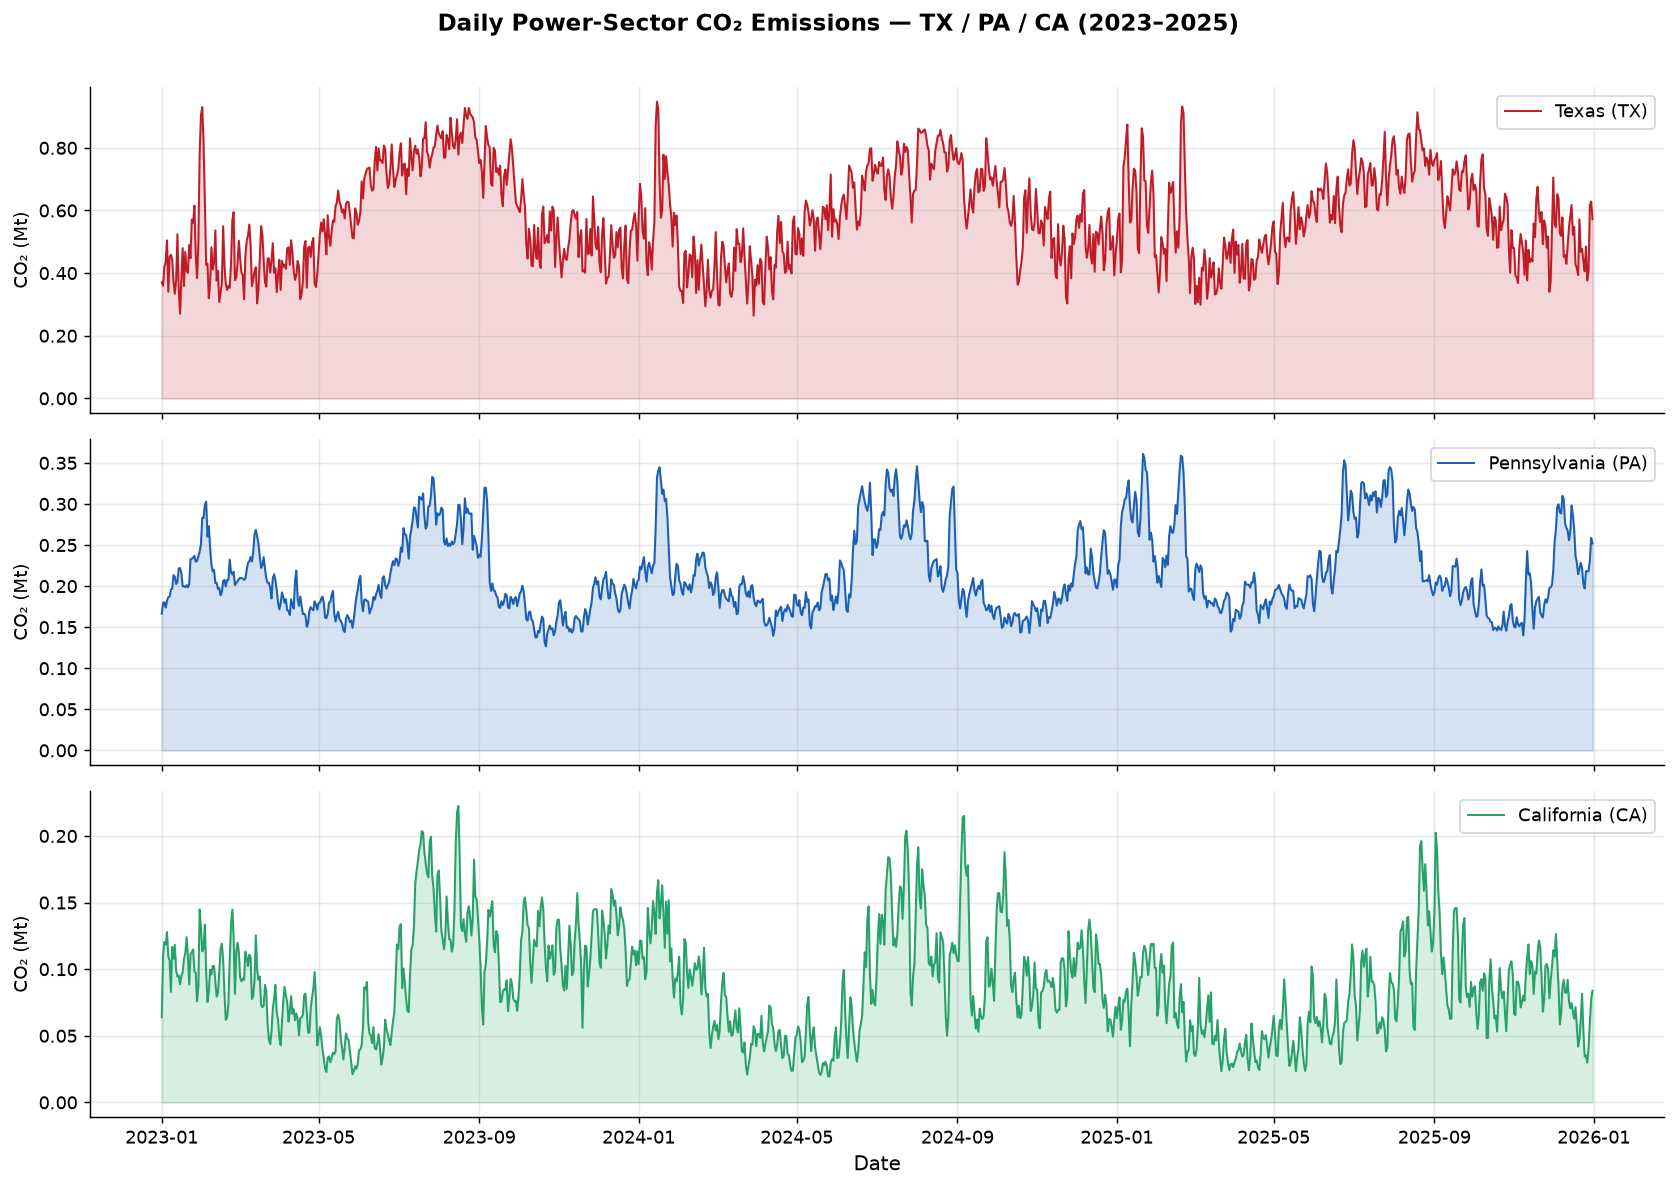

Saved 17a_co2_timeseries.png


In [25]:
# ── 17a: CO₂ time series — TX / PA / CA (2023–2025) ────────────────────
ts = pd.read_csv(f'{DATA_DIR}/state_daily_TX_PA_CA_2023_2025.csv', parse_dates=['date'])

STATE_COLORS = {'TX': '#c01c28', 'PA': '#1a5fb4', 'CA': '#26a269'}
STATE_LABELS = {'TX': 'Texas (TX)', 'PA': 'Pennsylvania (PA)', 'CA': 'California (CA)'}

fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
fig.suptitle('Daily Power-Sector CO₂ Emissions — TX / PA / CA (2023–2025)',
             fontsize=13, fontweight='bold', y=1.01)

for ax, state in zip(axes, ['TX', 'PA', 'CA']):
    sub = ts[ts.state == state].sort_values('date')
    ax.fill_between(sub.date, sub.co2_mass / 1e6, alpha=0.18, color=STATE_COLORS[state])
    ax.plot(sub.date, sub.co2_mass / 1e6, color=STATE_COLORS[state], linewidth=1.1,
            label=STATE_LABELS[state])
    ax.set_ylabel('CO₂ (Mt)', fontsize=10)
    ax.legend(loc='upper right', framealpha=0.8)
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.2f'))

axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/17a_co2_timeseries.png', bbox_inches='tight')
plt.show()
print('Saved 17a_co2_timeseries.png')


### 17b — Single-Split Benchmark: Ridge vs HGB vs Persistence

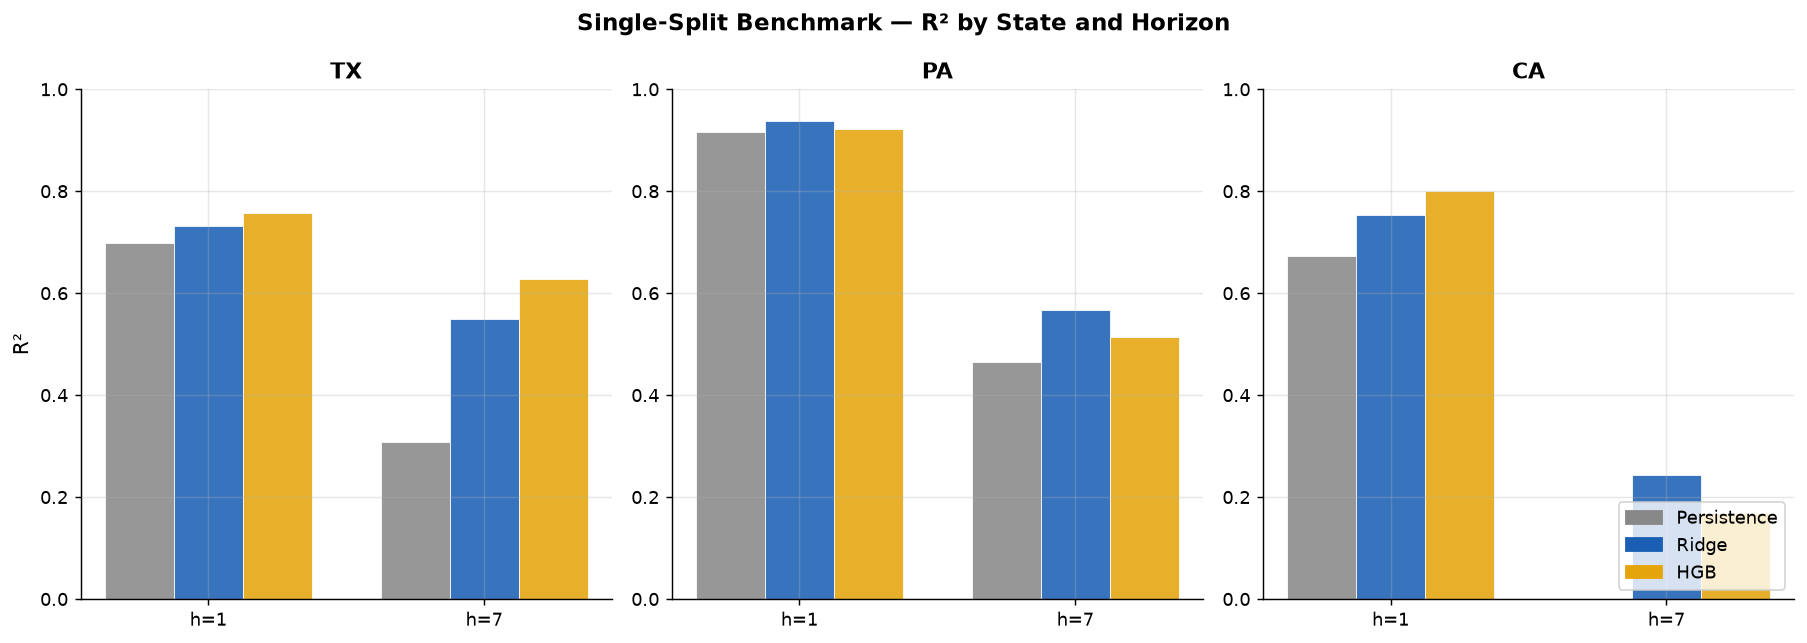

Saved 17b_single_split_benchmark.png


In [26]:
# ── 17b: Single-split benchmark — Ridge vs HGB vs Persistence ───────────
ss = pd.read_csv(f'{DATA_DIR}/single_split_benchmark.csv')
horizons = sorted(ss.Horizon.unique())
states   = ['TX', 'PA', 'CA']
models   = ['Persistence', 'Ridge', 'HistGradientBoosting']
model_labels = {'Persistence': 'Persistence', 'Ridge': 'Ridge', 'HistGradientBoosting': 'HGB'}

fig, axes = plt.subplots(1, 3, figsize=(14, 5), sharey=False)
fig.suptitle('Single-Split Benchmark — R² by State and Horizon',
             fontsize=13, fontweight='bold')

x = np.arange(len(horizons))
width = 0.25

for ax, state in zip(axes, states):
    sub = ss[ss.State == state]
    for j, model in enumerate(models):
        vals = [sub[(sub.Horizon == h) & (sub.Model == model)]['R2'].values[0]
                if len(sub[(sub.Horizon == h) & (sub.Model == model)]) > 0 else np.nan
                for h in horizons]
        ax.bar(x + j * width, vals,
               width=width,
               label=model_labels[model],
               color=PALETTE.get(model_labels[model], '#aaa'),
               alpha=0.87, edgecolor='white', linewidth=0.5)
    ax.set_xticks(x + width)
    ax.set_xticklabels([f'h={h}' for h in horizons])
    ax.set_title(state, fontsize=12, fontweight='bold')
    ax.set_ylabel('R²') if state == 'TX' else None
    ax.set_ylim(0, 1)

handles = [mpatches.Patch(color=PALETTE.get(model_labels[m], '#aaa'),
           label=model_labels[m]) for m in models]
axes[-1].legend(handles=handles, loc='lower right')
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/17b_single_split_benchmark.png', bbox_inches='tight')
plt.show()
print('Saved 17b_single_split_benchmark.png')


### 17c — Effect Sizes with 95% Confidence Intervals

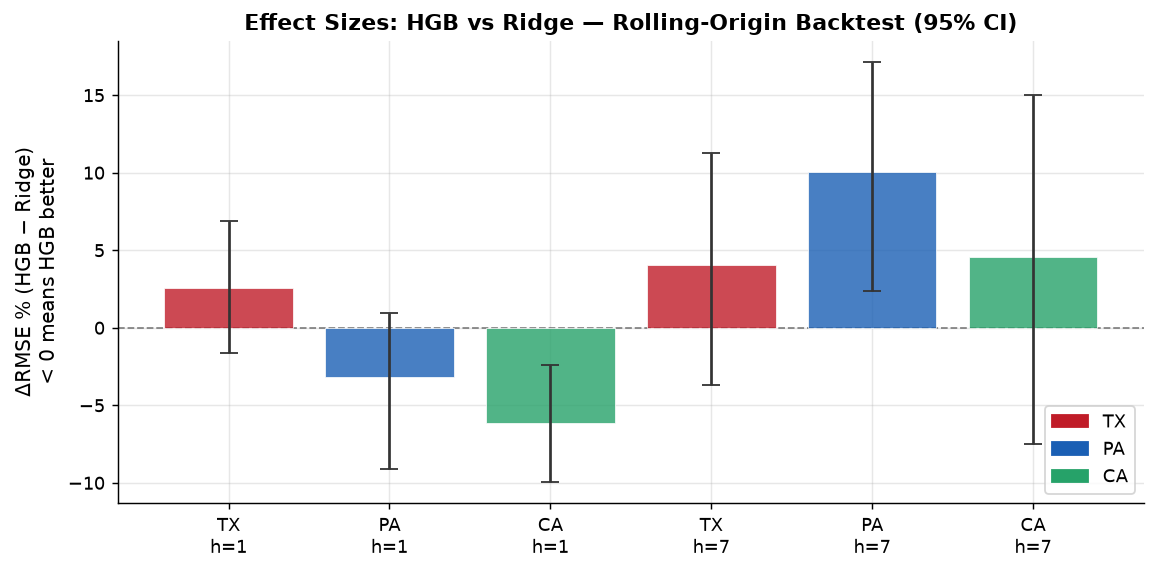

Saved 17c_effect_sizes.png


In [27]:
# ── 17c: Effect sizes with 95% CI — Rolling origin (TX / PA / CA) ───────
ef = pd.read_csv(f'{DATA_DIR}/effect_sizes.csv')

fig, ax = plt.subplots(figsize=(9, 4.5))
STATE_COLORS2 = {'TX': '#c01c28', 'PA': '#1a5fb4', 'CA': '#26a269'}
x = np.arange(len(ef))
colors = [STATE_COLORS2.get(s, '#888') for s in ef.State]

ax.axhline(0, color='#555', linewidth=1, linestyle='--', alpha=0.7)
ax.bar(x, ef.DeltaRMSE_pct_HGBvsRidge, color=colors, alpha=0.8,
       edgecolor='white', linewidth=0.5, zorder=3)
ax.errorbar(x, ef.DeltaRMSE_pct_HGBvsRidge,
            yerr=[ef.DeltaRMSE_pct_HGBvsRidge - ef.CI95_lo,
                  ef.CI95_hi - ef.DeltaRMSE_pct_HGBvsRidge],
            fmt='none', color='#333', capsize=5, linewidth=1.5, zorder=4)
ax.set_xticks(x)
ax.set_xticklabels([f"{r.State}\nh={r.Horizon}" for _, r in ef.iterrows()], fontsize=10)
ax.set_ylabel('ΔRMSE % (HGB − Ridge)\n< 0 means HGB better')
ax.set_title('Effect Sizes: HGB vs Ridge — Rolling-Origin Backtest (95% CI)',
             fontsize=12, fontweight='bold')

patches = [mpatches.Patch(color=c, label=s) for s, c in STATE_COLORS2.items()]
ax.legend(handles=patches, loc='lower right')
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/17c_effect_sizes.png', bbox_inches='tight')
plt.show()
print('Saved 17c_effect_sizes.png')


### 17d — Multihorizon Crossover: The Paper's Primary Finding

ValueError: x and y must have same first dimension, but have shapes (7,) and (1,)

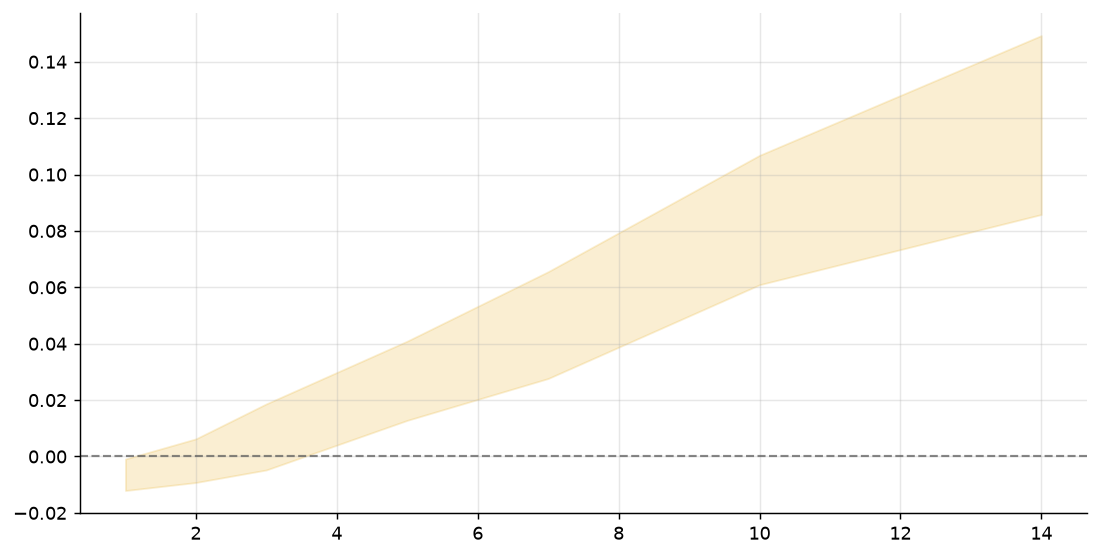

In [28]:
# ── 17d: Multihorizon crossover — paper's primary finding ────────────────
mh = pd.read_csv(f'{DATA_DIR}/multihorizon_summary.csv')
mh['gap'] = mh.R2_HGB - mh.R2_ridge

# Median and IQR of (R2_HGB - R2_ridge) per horizon across all 45 states
summary = mh.groupby('horizon')['gap'].agg(['median', 'mean',
    lambda x: x.quantile(0.25), lambda x: x.quantile(0.75)]).reset_index()
summary.columns = ['horizon', 'median', 'mean', 'q25', 'q75']

fig, ax = plt.subplots(figsize=(10, 5))
ax.axhline(0, color='#555', linewidth=1.2, linestyle='--', alpha=0.7, label='No difference')
ax.fill_between(summary.horizon, summary.q25, summary.q75,
                alpha=0.18, color='#e5a50a', label='IQR (25–75%)')
ax.plot(summary.horizon, summary.median, 'o-', color='#e5a50a',
        linewidth=2.2, markersize=7, label='Median (HGB − Ridge)', zorder=5)
ax.plot(summary.horizon, summary.mean, 's--', color='#1a5fb4',
        linewidth=1.5, markersize=5, alpha=0.8, label='Mean (HGB − Ridge)')

ax.set_xlabel('Forecast Horizon (days)')
ax.set_ylabel('ΔR² (HGB − Ridge)')
ax.set_title('Multihorizon Crossover: HGB vs Ridge\n'
             '45 states × 7 horizons — Forecast horizon governs model advantage',
             fontsize=12, fontweight='bold')
ax.set_xticks(summary.horizon)
ax.legend()

# Annotate crossover
cross_h = summary.loc[(summary.median >= 0).idxmax(), 'horizon'] if any(summary.median >= 0) else None
if cross_h is not None:
    ax.axvline(cross_h, color='#a51d2d', linewidth=1, linestyle=':', alpha=0.8)
    ax.text(cross_h + 0.1, ax.get_ylim()[0] + 0.01,
            f'  crossover\n  ~h={cross_h}', color='#a51d2d', fontsize=9)

plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/17d_multihorizon_crossover.png', bbox_inches='tight')
plt.show()
print('Saved 17d_multihorizon_crossover.png')


### 17e — R² Distribution Across States (Box Plots by Horizon)

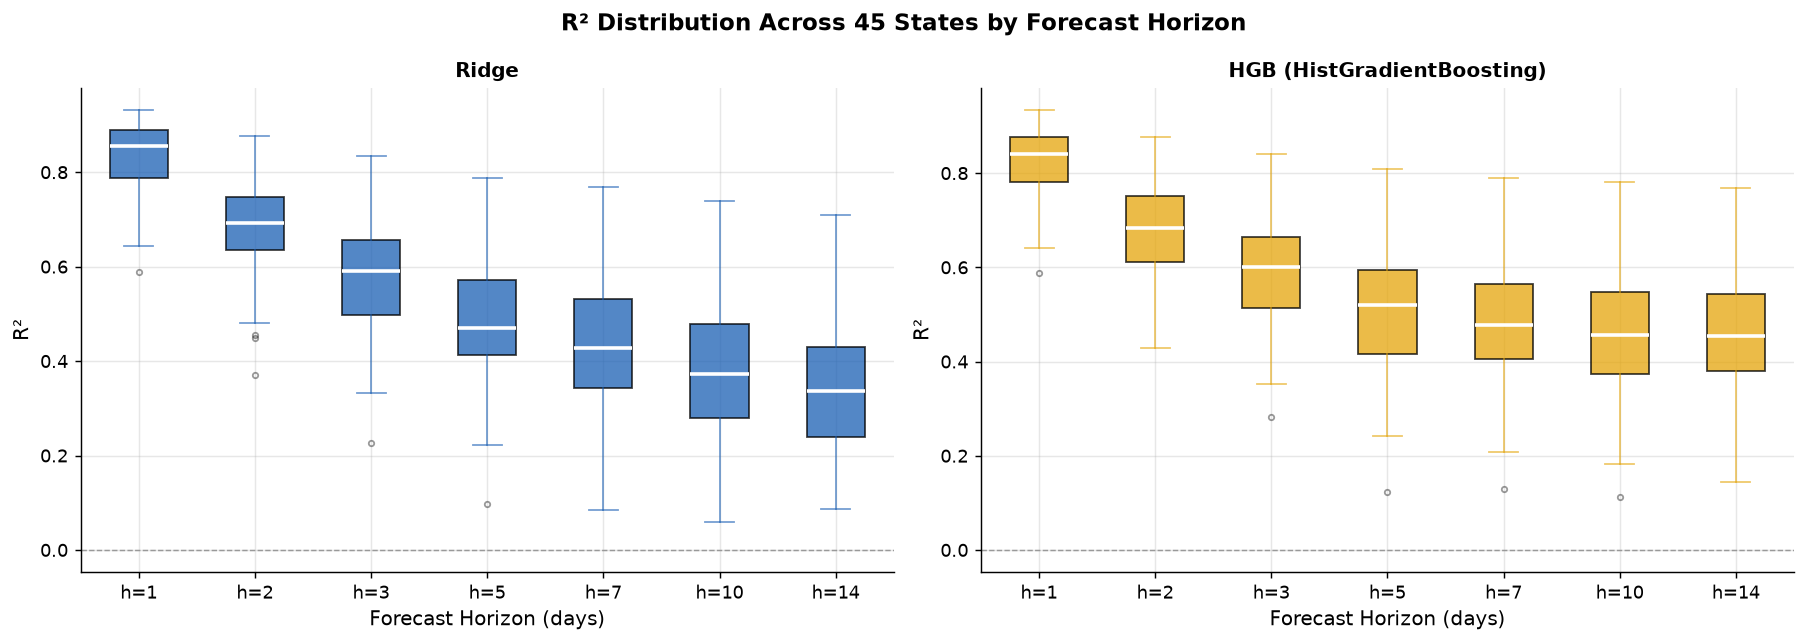

Saved 17e_r2_distribution_boxplots.png


In [29]:
# ── 17e: R² distribution across states — box plots by horizon ───────────
mh = pd.read_csv(f'{DATA_DIR}/multihorizon_summary.csv')

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
fig.suptitle('R² Distribution Across 45 States by Forecast Horizon',
             fontsize=13, fontweight='bold')

for ax, col, color, label in zip(
    axes,
    ['R2_ridge', 'R2_HGB'],
    ['#1a5fb4', '#e5a50a'],
    ['Ridge', 'HGB (HistGradientBoosting)'],
):
    data_by_h = [mh[mh.horizon == h][col].values for h in sorted(mh.horizon.unique())]
    bp = ax.boxplot(data_by_h, patch_artist=True,
                   medianprops=dict(color='white', linewidth=2),
                   whiskerprops=dict(color=color, alpha=0.6),
                   capprops=dict(color=color, alpha=0.6),
                   flierprops=dict(marker='o', markersize=3, alpha=0.4, color=color))
    for patch in bp['boxes']:
        patch.set_facecolor(color)
        patch.set_alpha(0.75)
    ax.set_xticklabels([f'h={h}' for h in sorted(mh.horizon.unique())])
    ax.set_xlabel('Forecast Horizon (days)')
    ax.set_ylabel('R²')
    ax.set_title(label, fontsize=11, fontweight='bold')
    ax.axhline(0, color='#999', linewidth=0.8, linestyle='--')

plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/17e_r2_distribution_boxplots.png', bbox_inches='tight')
plt.show()
print('Saved 17e_r2_distribution_boxplots.png')


### 17f — Model Advantage Heatmap (State × Horizon)

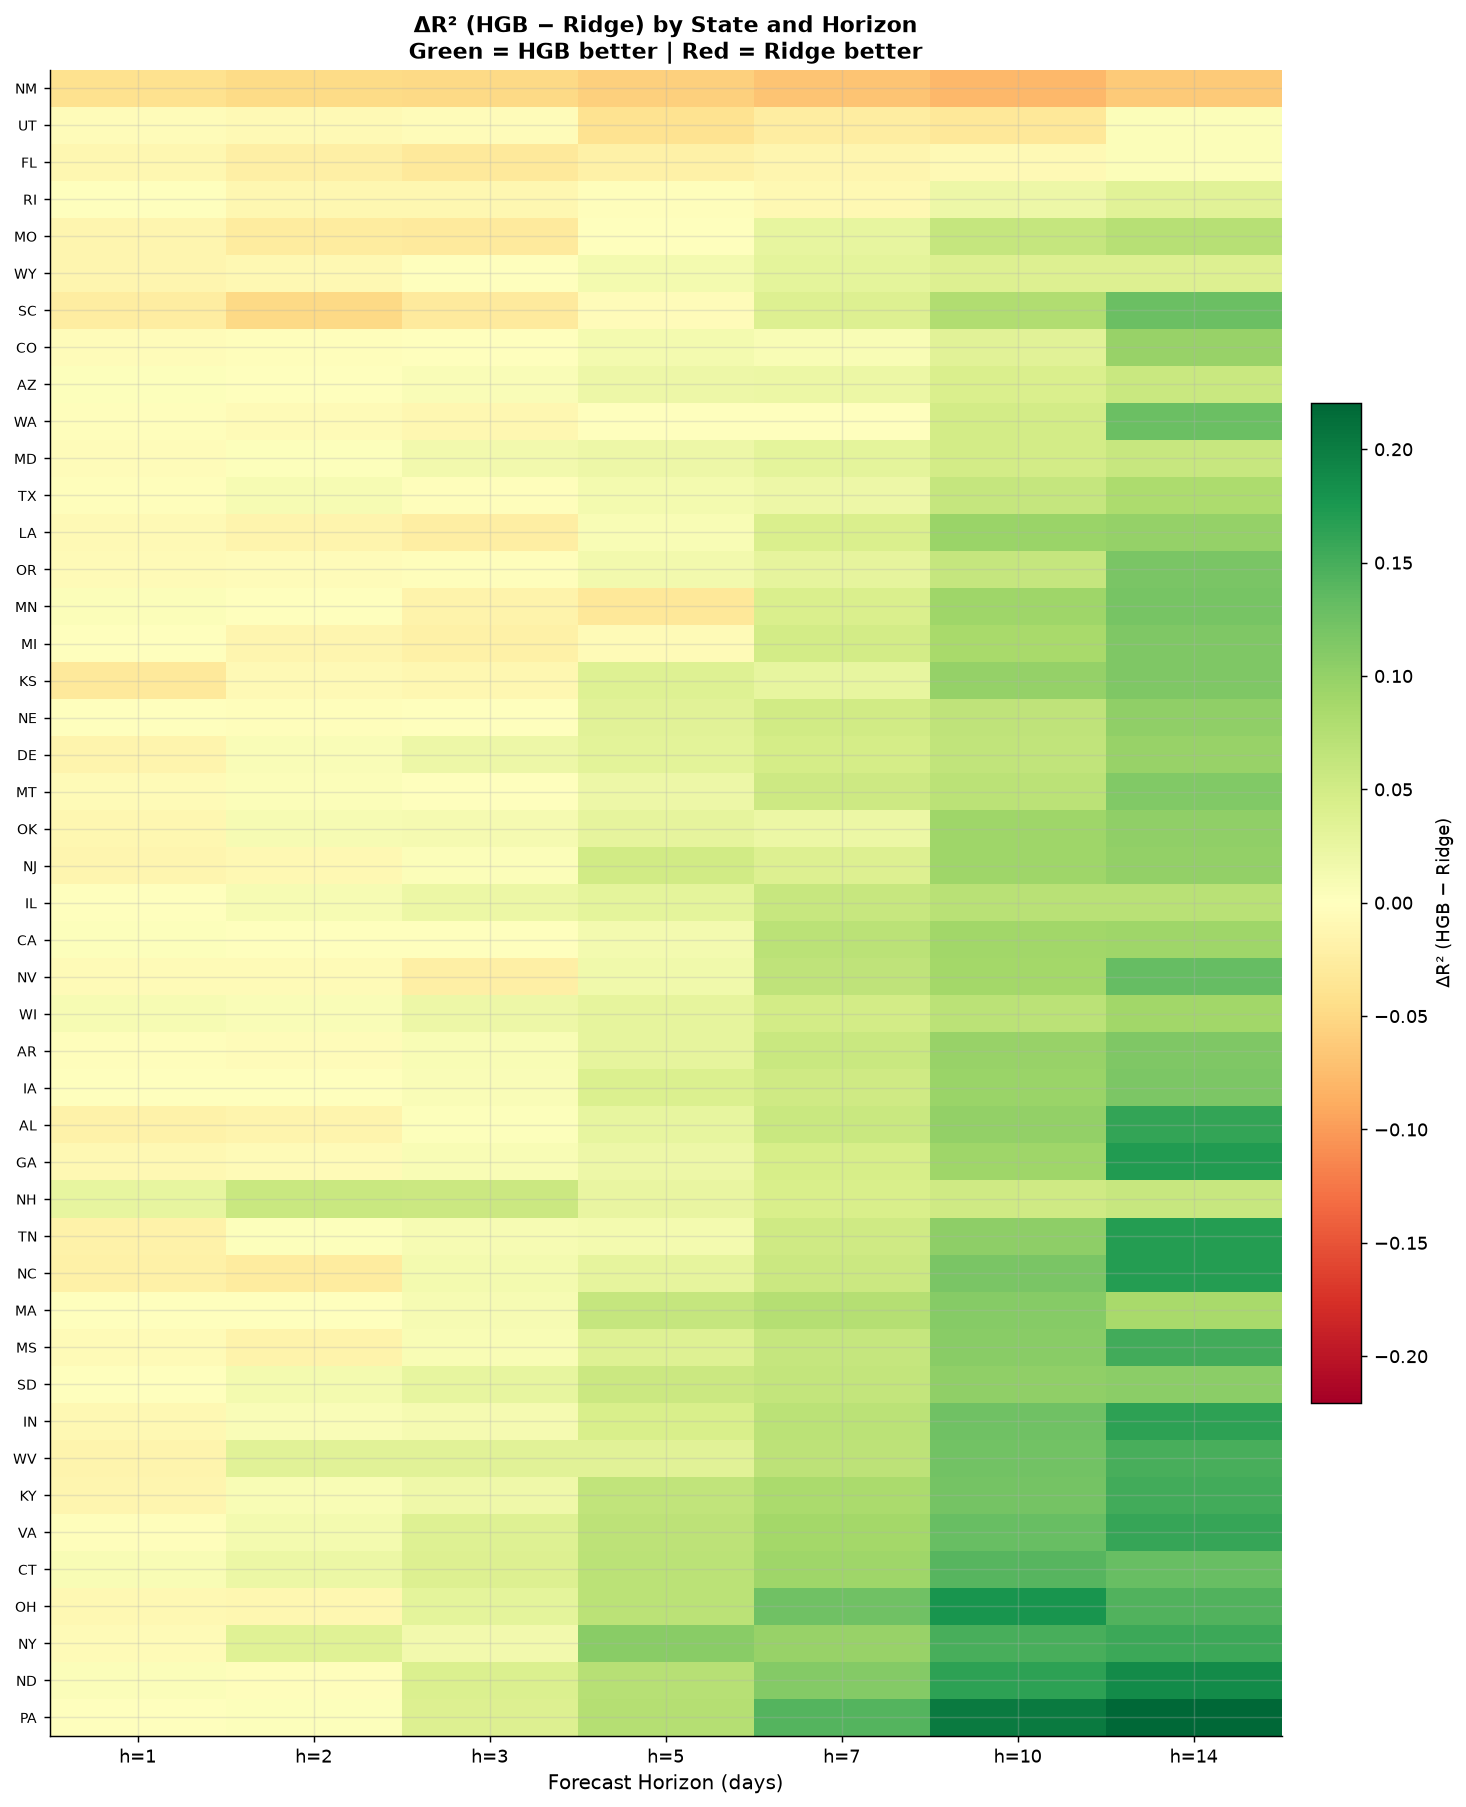

Saved 17f_model_advantage_heatmap.png


In [30]:
# ── 17f: Model advantage heatmap — state × horizon ───────────────────────
mh = pd.read_csv(f'{DATA_DIR}/multihorizon_dm_tests_corrected.csv')
mh['gap'] = mh.R2_HGB - mh.R2_ridge

# Pivot: rows = states sorted by mean gap, cols = horizons
pivot = mh.pivot_table(index='state', columns='horizon', values='gap')
state_order = pivot.mean(axis=1).sort_values().index
pivot = pivot.loc[state_order]

fig, ax = plt.subplots(figsize=(12, 14))
import matplotlib.colors as mcolors
cmap = plt.cm.RdYlGn
vmax = max(abs(pivot.values[~np.isnan(pivot.values)]).max(), 0.01)
im = ax.imshow(pivot.values, aspect='auto', cmap=cmap,
               vmin=-vmax, vmax=vmax, interpolation='nearest')

ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels([f'h={h}' for h in pivot.columns], fontsize=10)
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index, fontsize=8)
ax.set_xlabel('Forecast Horizon (days)')
ax.set_title('ΔR² (HGB − Ridge) by State and Horizon\n'
             'Green = HGB better | Red = Ridge better',
             fontsize=12, fontweight='bold')

cbar = plt.colorbar(im, ax=ax, shrink=0.6, pad=0.02)
cbar.set_label('ΔR² (HGB − Ridge)', fontsize=10)
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/17f_model_advantage_heatmap.png', bbox_inches='tight')
plt.show()
print('Saved 17f_model_advantage_heatmap.png')


### 17g — Nationwide Predictions vs Actuals (h = 1)

In [ ]:
# ── 17g: Nationwide predictions vs actuals — h=1, sample of states ───────
preds = pd.read_csv(f'{DATA_DIR}/nationwide_predictions.csv', parse_dates=['date'])
sample_states = ['TX', 'CA', 'FL', 'OH', 'NY']
h1 = preds[(preds.horizon == 1) & (preds.state.isin(sample_states))]

fig, axes = plt.subplots(len(sample_states), 1, figsize=(13, 12), sharex=False)
fig.suptitle('Nationwide Predictions vs Actuals — Horizon = 1 day (Sample States)',
             fontsize=13, fontweight='bold', y=1.01)

for ax, state in zip(axes, sample_states):
    sub = h1[h1.state == state].sort_values('date')
    if sub.empty:
        ax.text(0.5, 0.5, f'{state}: no data', ha='center', transform=ax.transAxes)
        continue
    scale = sub.y_true.max()
    ax.plot(sub.date, sub.y_true / scale, color='#333', linewidth=1.2,
            label='Actual', zorder=5)
    ax.plot(sub.date, sub.pred_ridge / scale, color='#1a5fb4', linewidth=1,
            alpha=0.8, linestyle='--', label='Ridge')
    ax.plot(sub.date, sub.pred_hgb / scale, color='#e5a50a', linewidth=1,
            alpha=0.8, linestyle=':', label='HGB')
    ax.set_ylabel('Norm. CO₂', fontsize=9)
    ax.set_title(state, fontsize=10, fontweight='bold', loc='left')
    if state == sample_states[0]:
        ax.legend(loc='upper right', fontsize=8, ncol=3)

axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/17g_nationwide_predictions.png', bbox_inches='tight')
plt.show()
print('Saved 17g_nationwide_predictions.png')


### 17h — GAM Mediation Scatter (All 45 States × 7 Horizons)

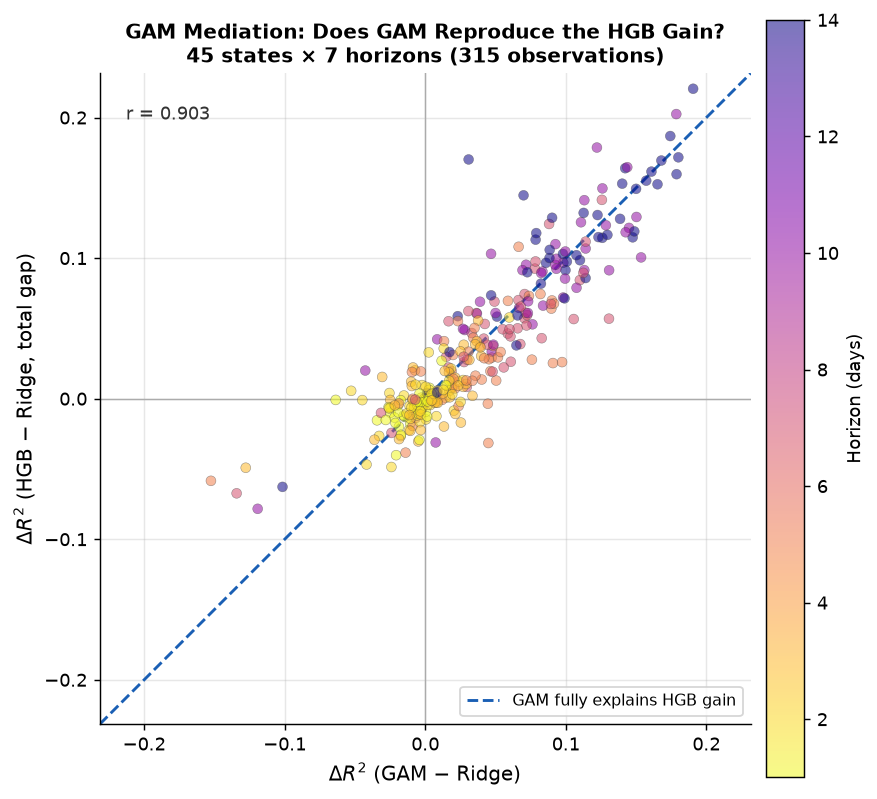

Saved 17h_gam_mediation_scatter.png


In [32]:
# ── 17h: GAM mediation scatter — all 45 states × 7 horizons ─────────────
gam = pd.read_csv(f'{DATA_DIR}/gam_national_vs_ridge_hgb.csv')

fig, ax = plt.subplots(figsize=(7, 6.5))
sc = ax.scatter(gam.gam_minus_ridge, gam.total_gap,
                c=gam.horizon, cmap='plasma_r', alpha=0.55, s=30,
                edgecolor='#444', linewidth=0.3, zorder=3)

# Identity line
lim = max(abs(gam[['gam_minus_ridge','total_gap']].values).max() * 1.05, 0.05)
ax.plot([-lim, lim], [-lim, lim], '--', color='#1a5fb4',
        linewidth=1.6, label='GAM fully explains HGB gain', zorder=2)
ax.axhline(0, color='#aaa', linewidth=0.8, zorder=1)
ax.axvline(0, color='#aaa', linewidth=0.8, zorder=1)

ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_aspect('equal')
ax.set_xlabel(r'$\Delta R^2$ (GAM $-$ Ridge)', fontsize=11)
ax.set_ylabel(r'$\Delta R^2$ (HGB $-$ Ridge, total gap)', fontsize=11)
ax.set_title('GAM Mediation: Does GAM Reproduce the HGB Gain?\n'
             '45 states × 7 horizons (315 observations)', fontsize=11, fontweight='bold')

cbar = plt.colorbar(sc, ax=ax, pad=0.02)
cbar.set_label('Horizon (days)', fontsize=10)

r_val = gam.gam_minus_ridge.corr(gam.total_gap)
ax.text(0.04, 0.95, f'r = {r_val:.3f}', transform=ax.transAxes,
        fontsize=10, va='top', color='#333')
ax.legend(fontsize=9, loc='lower right')
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/17h_gam_mediation_scatter.png', bbox_inches='tight')
plt.show()
print('Saved 17h_gam_mediation_scatter.png')


### Summary Table — Key Results from Pre-computed Data

In [33]:
# ── Summary table: key results from pre-computed data ────────────────────
from IPython.display import display, HTML

mh = pd.read_csv(f'{DATA_DIR}/multihorizon_summary.csv')
mh['gap'] = mh.R2_HGB - mh.R2_ridge
mh['winner'] = mh.gap.apply(lambda x: 'HGB' if x > 0 else 'Ridge')

print('=== Multihorizon Results: Mean R² and Model Advantage by Horizon ===')
tbl = mh.groupby('horizon').agg(
    N_states=('state', 'nunique'),
    Mean_R2_Ridge=('R2_ridge', 'mean'),
    Mean_R2_HGB=('R2_HGB', 'mean'),
    Mean_gap=('gap', 'mean'),
    Pct_HGB_wins=('winner', lambda x: (x=='HGB').mean() * 100),
).round(4)
display(tbl)

print('\n=== Three-State Rolling-Origin Summary ===')
ro = pd.read_csv(f'{DATA_DIR}/rolling_origin_summary.csv')
display(ro[['State','Horizon','Model','R2','RMSE','MAPE']].round(4))


=== Multihorizon Results: Mean R² and Model Advantage by Horizon ===


,N_states,Mean_R2_Ridge,Mean_R2_HGB,Mean_gap,Pct_HGB_wins
horizon,,,,,
1,45,0.8228,0.8162,-0.0065,20.0000
2,45,0.6717,0.6700,-0.0017,44.4444
3,45,0.5808,0.5861,0.0053,62.2222
5,45,0.4835,0.5094,0.0259,80.0000
7,45,0.4355,0.4832,0.0477,88.8889
10,45,0.3780,0.4617,0.0837,93.3333
14,45,0.3457,0.4542,0.1084,97.7778



=== Three-State Rolling-Origin Summary ===


,State,Horizon,Model,R2,RMSE,MAPE
0,TX,1,Persistence,0.7163,73347.9165,10.3143
1,TX,1,Ridge,0.7451,69517.1864,10.1485
2,TX,1,HistGradientBoosting,0.7591,67584.6618,9.7110
3,PA,1,Persistence,0.9116,15830.7736,5.2261
4,PA,1,Ridge,0.9294,14151.8490,4.7369
5,PA,1,HistGradientBoosting,0.9225,14826.2780,4.8438
6,CA,1,Persistence,0.7658,17947.2051,17.6523
7,CA,1,Ridge,0.8337,15125.1066,14.7829
8,CA,1,HistGradientBoosting,0.8189,15781.0929,15.5120
